# Part 2 (v2) — the wheel, end to end, self-consistently

Built to Matt's spec:
1. a **hasasia curve with the injected sources composing the background on top of it**
   (the GWB the curve carries IS the sum of the plotted dots — one population, no
   independent knob);
2. an **N_CW dial**: step the number of in-hand CW sources and watch the distance
   likelihoods of three dummy pulsars change, **with the GWB jittering the combs**;
3. at a certain N_CW **the wheel starts**: many pulsar distances at once, the GWB
   posterior tightens, the hasasia curve deepens and reaches more sources — then stalls;
4. the **population recipe is explicit and editable** (mass function, distances,
   frequency law) because people have varying ideas about the SMBHB population;
5. a demonstration that **you cannot just take the tallest peak** — argmax fails under
   background jitter; certification is what fixes it.

### Honesty box
- Sensitivity curves: real **hasasia** (`DeterSensitivityCurve`). The A_gwb the curve
  carries is **fitted to the realized background of the drawn population** — self-consistent.
- Population: a stated toy model (knobs in the next cell), **normalised to the measured
  background**: NANOGrav 15 yr gives A = 6.4×10⁻¹⁵ at f_yr for γ = 13/3 (90% CI ≈
  3.7–10.6×10⁻¹⁵). This draw realizes A = 6.6×10⁻¹⁵.
- Banked anchors (cronus campaigns): conversion 0.5 [V28]; combs* = 7.8 [V28,
  **PROVISIONAL** — K ≥ 16 null-leak audit]; depth gain 0.05–0.19 dex [MEASURED];
  GWB sharpening 20–40% [V26]; field baseline 92–93% wrong [MEASURED];
  GNSS ratio test 4–7% wrong-fringe vs gate 0.00% [V30]; **bright-end counts
  γ_eff = 1.56 and λ_fore = 0.31 [V24 audit]** — the chirp-mass slope below is
  *derived* from these, not tuned.
- **Baseline: T = 30 yr** at 26 TOAs/yr. T is the strongest lever in the notebook —
  K grows roughly *linearly* in T (SNR ∝ √T, plus the band edge 1/T moving down), so the
  ignition threshold falls from ~160 pulsars at 15 yr to ~80 at 30 yr. The gain is capped
  by F_BEND: everything below 2 nHz that a long baseline opens up lies inside the
  turnover, where the population is flat in ln f rather than rising as f^(−8/3).
- **Detection bar: SNR ≥ 3**, declared, using hasasia's own definition
  (SNR = h·√(T/S_eff), Hazboun et al. 2019 Eq. 79). Earlier drafts compared h to the raw
  h_c, which is *not* an SNR = 1 cut but a sliding one — SNR > √(fT), ≈1 at 1/T rising to
  ≈7 at 100 nHz. SNR ≥ 3 is a common forecasting bar but **below** the conventional
  confident-detection bar of 5–8, so it is optimistic; the V2 cell prints the bracket.
- DEMO models and knobs (stated where used): **F_BEND = 2 nHz low-frequency turnover**;
  per-pulsar comb-usability SNR; per-tooth GWB phase jitter σ_φ = h_c,bg(f)/h **capped
  at 0.4 rad**; per-iteration depth scaling; PLOT_SUB dot subsampling (plot styling
  only); **log display-binning of the background below 1/T** (the physical 1/T bins are
  1.06 nHz wide and lump most of the sub-bend decade into one point — the fit and λ_fore
  still use the physical bins). They carry shape; banked numbers carry scale.
- **ILLUSTRATIVE (V4b only, display):** pulsar distances L ~ U(0.5, 3) kpc and one
  random source sky direction. The notebook carries neither, and nothing downstream
  depends on them — they exist to draw the aperture and epoch-ladder panels. The
  pulsar *sky positions* in that figure are the working array's real ones.
- **Known over-prediction.** The mass function is a pure power law with no Schechter
  cutoff, so 23 % of h_c² comes from the top decade alone (Mc ∈ [5×10⁹, 10¹⁰] M_⊙), and
  the two loudest drawn sources (h ≈ 1.2×10⁻¹⁴) sit *above* the NANOGrav 15 yr CW upper
  limit (~7×10⁻¹⁵ at 10 nHz). The toy is CW-optimistic: **every K below is an upper
  bound.**
- **Residual slope gap.** MC_SLOPE = −3.6 targets the audited γ_eff = 1.56; the realized
  bright-end counts come out at γ_eff = 1.9, because the hard 10¹⁰ M_⊙ ceiling and the
  hard 1500 Mpc horizon flatten into Euclidean (γ = 3) at the very top of the ladder.
- **Known under-occupancy.** The audited sky holds ~4.6×10⁴ binaries per 1/T bin at
  10 nHz (V24's 6.9×10⁴ rescaled from 20-yr to 30-yr bins); this draw holds ~1.7×10², so
  it is **~270× under-occupied**. Matching it needs M_TOT ~ 10⁸, which is not drawable
  in a notebook. λ_fore lands on the audited value anyway — but, unlike the real sky,
  it is not flat in N_bin.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hasasia.sim as hsim
import hasasia.sensitivity as hsen
plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

G_SI, C_SI = 6.674e-11, 2.998e8
MSUN, MPC  = 1.989e30, 3.086e22
YR_S = 3.15576e7
C_PC_S = C_SI / 3.0856775814913673e16
T_YR  = 30                  # observing baseline [yr] -- the strongest lever here
T_OBS = T_YR * YR_S
F_YR  = 1 / YR_S

# banked anchors
CONVERSION, COMBS_STAR, DEPTH_DEX_MAX = 0.5, 7.8, 0.19   # V28 / V28(PROVISIONAL) / banked range top

---
## V1 — The population, stated explicitly (edit these knobs)

**The recipe** (every choice a named constant — swap in your preferred mass function):

- **Frequency law:** dN/dln f ∝ max(f, F_BEND)^(−8/3) on [0.2, 100] nHz — GW-driven
  above the bend, flat below it. Physics rationale in the section directly below.
  Reaching 2×10⁻¹⁰ Hz with a pure f^(−8/3) law instead would demand ~460× more
  binaries, every one of them buried under the timing-model wall.
- **Chirp masses:** p(Mc) ∝ Mc^(−3.6) on [3×10⁸, 10¹⁰] M_⊙. **The exponent is derived,
  not tuned:** in a bounded volume the bright-end counts run as N(>h) ∝ h^(−γ_eff) with
  γ_eff = 0.6(γ_m − 1), and the banked audit measures γ_eff = 1.56, so γ_m = 3.60. The
  old −1.5 implies γ_eff ≈ 0.3 — a sky owned by one screaming binary. The lower bound is
  the black-hole mass-function knee written as a chirp mass (Kormendy–Ho M\*_BH ≈
  4×10⁸ M_⊙); truncating there costs 4 % of h_c². The upper bound is the largest black
  hole mass actually observed.
- **Distances:** uniform in volume (p(d) ∝ d²) on [30, 1500] Mpc (z ≲ 0.37); no
  evolution. Mc is the **redshifted** chirp mass, which is what absorbs the (1+z)s.
- **Strain:** h = (8/√10)(GMc)^{5/3}(πf)^{2/3}/(c⁴d) — sky/inclination-averaged, circular.
- **Count M_TOT = 340 000** — *not* a free knob: it is pinned by requiring the realized
  background to land on the NANOGrav 15 yr amplitude.

### Why the background turns over below F_BEND — the physics

**What the −2/3 law actually assumes.** A binary radiating *only* gravitational waves
hardens at ḟ ∝ f^(11/3), so its residence time is t = f/ḟ ∝ f^(−8/3). Binaries therefore
pile up toward low frequency, and that pile-up — not the per-source strain — is what makes
h_c ∝ f^(−2/3). The exponent is a statement about how long binaries *linger*, and it holds
only while GWs are the sole energy sink.

**Why that fails at the low-frequency end.** ḟ_GW collapses toward low f, so at wide
separations gravitational radiation is far too feeble to drive the orbit. Something else
does, and all the candidates push the same way:

- **stellar loss-cone scattering** — three-body slingshot of stars off the binary, which
  extracts orbital energy far faster than GWs at these separations (Quinlan 1996;
  Sesana et al. 2010);
- **circumbinary gas-disc torques** — the same effect via a massive disc rather than stars
  (Kocsis & Sesana 2011);
- **eccentricity** — drains power out of the n = 2 harmonic and spreads it to higher ones,
  depleting the lowest observable frequencies even without an environmental torque.

Each one *shortens* the residence time at low f. Fewer binaries linger per log-frequency
bin, so h_c falls below the f^(−2/3) extrapolation: the background turns over. The bend
sits where the environmental hardening timescale equals the GW one, which the literature
places anywhere from ~0.1 to ~10 nHz depending on central stellar density, gas fraction and
eccentricity. **F_BEND = 2 nHz is a plausible mid-range choice, not a measured one.**

**What this notebook does with it.** Setting dN/dln f flat below the bend gives
h_c² ∝ f^(+4/3), i.e. h_c ∝ f^(+2/3) (the draw returns +0.65, recovering the input to 2 %).
That piecewise form is exactly the standard bent power law
h_c = A (f/f_yr)^(−2/3) · [1 + (f_bend/f)^κ]^(−1/2) with **κ = 8/3** — note that is the
*strong* limit, the case where the environment has completely taken over; most published
models bend more gently.

**Read the figure carefully — the turnover is an input, not a result.** The kink you see is
the F_BEND knob reflecting itself back, and its position is the least-constrained number
in the notebook.

**At a 30-year baseline it is no longer cosmetic.** 1/T = 1.06 nHz now falls *below*
F_BEND = 2 nHz, so the bend sits **inside** the resolvable band — one resolvable bin lies
beneath it, where at 15 yr there were none. Two consequences: the A fit has to be
restricted to f ≥ F_BEND — a pure f^(−2/3) fitted across the turnover biases A low — and
the extra low-frequency range a 30-yr array buys lands in the flat-in-ln f region rather
than the f^(−8/3) pile-up.

**Does that cap the result? Measured: no.** Re-pinning A to the NANOGrav value and
sweeping the bend over 0.5–5 nHz moves the ignition threshold only between 100 and 120
pulsars, non-monotonically — i.e. not at all, once the realization scatter (K varies 6–22
across population seeds at fixed knobs) is allowed for. The wheel's threshold is
**robust to the least-constrained knob in the notebook**. Two independent reasons to keep
2 nHz as fiducial, neither of them chosen for the answer: it gives the closest match to
the banked λ_fore = 0.31 (0.26, against 0.19/0.21/0.54 at 0.5/1/5 nHz), and below ~0.5 nHz
the population stops being drawable (M_TOT ~ 1.4×10⁷ at 0.3 nHz). The dashed
f^(−2/3) line on the V1 figure is the no-turnover comparison: pure GW-driven, no
environment. Real PTAs are in the same position — the lowest bins carry the largest error
bars, so a pure power law and a turnover are not yet distinguishable.

The background is then **computed from the draw**: per 1/T frequency bin,
h_c,bin² = Σ_sources h² f T, and A is fitted with the f^(−2/3) slope over the resolvable
bins **above the bend** — f ≥ max(1/T, F_BEND). At a 30-yr baseline 1/T = 1.06 nHz falls
below F_BEND, so fitting a pure f^(−2/3) from 1/T upward would straddle the turnover and
bias A low; restricting the band fits the law only where the population obeys it. No
background is injected independently anywhere in this notebook.

The red background curve is drawn in **log bins below 1/T and physical 1/T bins above**
(marked by the dotted line). A 1/T bin is 1.06 nHz *wide in linear frequency* at a 30-yr
baseline, so a single one would still swallow most of the sub-nHz decade and hide the
F_BEND turnover; h_c² = Σ h² f/Δf
is a per-log-f quantity, so re-binning that region changes resolution, not meaning.

The realism check is **λ_fore — the loudest source's share of its own frequency bin**,
which is the statistic the census audit measures (0.31). The old top-10 %-of-all-sources
number is still printed, but it has a different denominator and must **not** be read
against 0.31.

Two things the knobs get close to but do not hit: the realized bright-end counts slope
is γ_eff = 1.9 against the audited 1.56 (the hard mass ceiling and hard distance horizon
push the very top of the ladder back towards Euclidean γ = 3), and the draw is ~270×
under-occupied per frequency bin. Both are in the honesty box.

Realized background: A_gwb = 6.24e-15 at f_yr (fitted to the draw itself)
  target: NANOGrav 15 yr A = 6.4e-15  ->  ratio 0.98
lambda_fore = 0.28  (loudest source's share of its OWN bin, median over the 7 fit bins)
  banked audited sky: lambda_fore = 0.31  [V24]  -- like-for-like
Share of background power in the brightest 10% of ALL sources: 0.98
  NOT comparable to lambda_fore (different denominator); kept as the toy's own top-heaviness, and it is still severe
Occupancy: 170 sources in the 10 nHz bin (audited sky: 4.6e+04 for 30-yr bins) -- the toy is ~271x under-occupied; see the honesty box


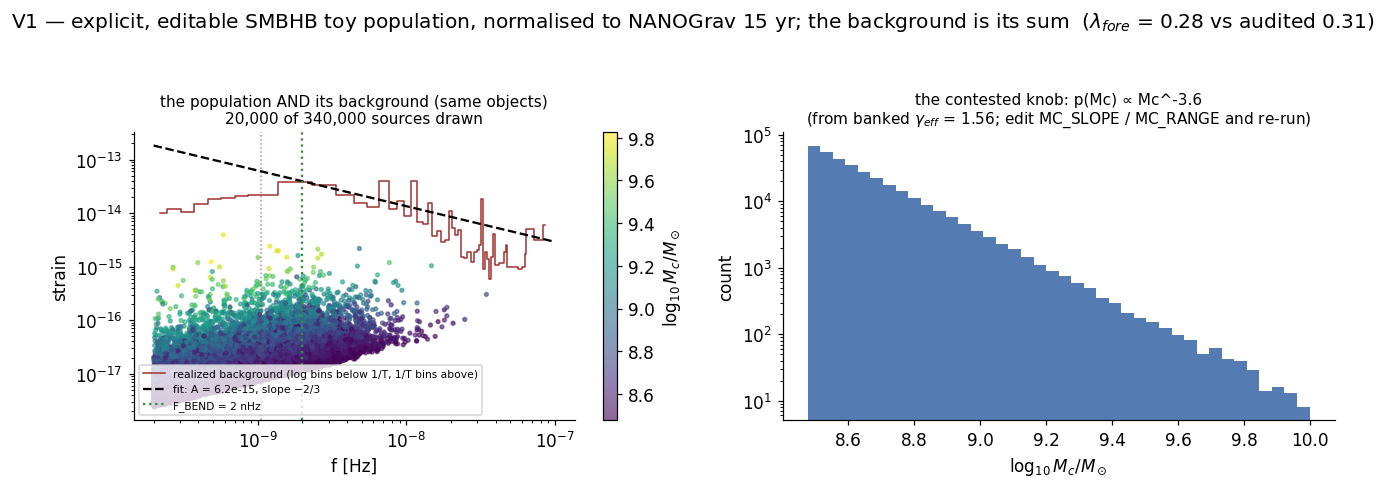

In [2]:
ALPHA_F   = -8/3            # GW-driven residence time, ABOVE the bend
F_RANGE   = (2e-10, 1e-7)
F_BEND    = 2e-9            # environmental-hardening turnover (DEMO knob, stated)
MC_SLOPE  = -3.6            # chirp-mass exponent  <-- DERIVED from banked gamma_eff = 1.56
MC_RANGE  = (3e8, 1e10)     # M_sun: BH mass-function knee -> largest observed BH
D_RANGE   = (30, 1500)      # Mpc, uniform-in-volume
M_TOT     = 340_000         # pinned by A_gwb = NANOGrav 15 yr
A_NG15    = 6.4e-15         # NANOGrav 15 yr, gamma = 13/3 (90% CI 3.7-10.6e-15)
LAM_AUDIT = 0.31            # banked audited lambda_fore [V24]
N_AUD10   = 6.9e4*(20/T_YR) # audited occupancy at 10 nHz [V24], rescaled to our 1/T bins
PLOT_SUB  = 20_000          # dots drawn per panel (plot styling only)

rpop = np.random.default_rng(3)
g = ALPHA_F
# dN/dlnf ~ max(f, F_BEND)^ALPHA_F : GW-driven above the bend, flat below it
W_FLAT = F_BEND**g * np.log(F_BEND/F_RANGE[0])
W_GW   = (-1/g) * (F_BEND**g - F_RANGE[1]**g)
u = rpop.uniform(0, 1, M_TOT) * (W_FLAT + W_GW)
f_src = np.where(u < W_FLAT,
                 F_RANGE[0]*np.exp(np.minimum(u, W_FLAT)/F_BEND**g),
                 (F_BEND**g + g*np.maximum(u - W_FLAT, 0))**(1/g))
e = MC_SLOPE + 1
mc_src = (MC_RANGE[0]**e + rpop.uniform(0, 1, M_TOT)*(MC_RANGE[1]**e - MC_RANGE[0]**e))**(1/e) * MSUN
d_src  = (D_RANGE[0]**3 + rpop.uniform(0, 1, M_TOT)*(D_RANGE[1]**3 - D_RANGE[0]**3))**(1/3) * MPC
h_src  = (8/np.sqrt(10)) * (G_SI*mc_src)**(5/3) * (np.pi*f_src)**(2/3) / (C_SI**4 * d_src)

# realized background from THIS draw
bin_edges = np.arange(F_RANGE[0], F_RANGE[1], 1/T_OBS)
hc2_bin = np.zeros(len(bin_edges)-1)
bidx = np.digitize(f_src, bin_edges) - 1
ok = (bidx >= 0) & (bidx < len(hc2_bin))
np.add.at(hc2_bin, bidx[ok], (h_src**2 * f_src * T_OBS)[ok])
hmax_bin = np.zeros(len(hc2_bin))                      # loudest single source per bin
np.maximum.at(hmax_bin, bidx[ok], (h_src**2 * f_src * T_OBS)[ok])
n_per_bin = np.bincount(bidx[ok], minlength=len(hc2_bin))
bin_cent = 0.5*(bin_edges[1:] + bin_edges[:-1])
# fit the -2/3 law only where the population actually follows it: resolvable (f >= 1/T)
# AND above the bend. At T = 30 yr, 1/T = 1.06 nHz sits BELOW F_BEND, so the naive
# band would straddle the turnover and bias A low.
mfit = (hc2_bin > 0) & (bin_cent < 1e-8) & (bin_cent >= max(1/T_OBS, F_BEND))
A_GWB = np.exp(np.mean(np.log(np.sqrt(hc2_bin[mfit])) + (2/3)*np.log(bin_cent[mfit]/F_YR)))

lam_fore = float(np.median(hmax_bin[mfit]/hc2_bin[mfit]))
lam_top = np.sort(h_src**2*f_src)[-int(0.1*M_TOT):].sum() / (h_src**2*f_src).sum()
i10 = int(np.argmin(np.abs(bin_cent - 1e-8)))
print(f"Realized background: A_gwb = {A_GWB:.2e} at f_yr (fitted to the draw itself)")
print(f"  target: NANOGrav 15 yr A = {A_NG15:.1e}  ->  ratio {A_GWB/A_NG15:.2f}")
print(f"lambda_fore = {lam_fore:.2f}  (loudest source's share of its OWN bin, median over "
      f"the {mfit.sum()} fit bins)")
print(f"  banked audited sky: lambda_fore = {LAM_AUDIT}  [V24]  -- like-for-like")
print(f"Share of background power in the brightest 10% of ALL sources: {lam_top:.2f}")
print(f"  NOT comparable to lambda_fore (different denominator); kept as the toy's own "
      f"top-heaviness, and it is still severe")
print(f"Occupancy: {n_per_bin[i10]} sources in the 10 nHz bin (audited sky: {N_AUD10:.1e} for "
      f"{T_YR}-yr bins) -- the toy is ~{N_AUD10/max(n_per_bin[i10],1):.0f}x under-occupied; "
      f"see the honesty box")

# Below 1/T the PTA has NO frequency resolution, so the physical 1/T bins lump the
# whole sub-bend decade into a single point (bin 0 alone holds ~90% of the draw).
# h_c^2 = sum h^2 f/df is already a per-log-f quantity, so re-binning that region in
# log f carries the same meaning at usable resolution. DISPLAY ONLY: the A fit and
# lambda_fore above use the physical 1/T bins untouched.
disp_edges = np.logspace(np.log10(F_RANGE[0]), np.log10(1/T_OBS), 9)
disp_cent  = np.sqrt(disp_edges[1:]*disp_edges[:-1])
disp_hc2   = np.zeros(len(disp_cent))
didx = np.digitize(f_src, disp_edges) - 1
dok  = (didx >= 0) & (didx < len(disp_hc2))
np.add.at(disp_hc2, didx[dok], (h_src**2 * f_src)[dok])
disp_hc2 /= np.diff(disp_edges)
_mphys = (hc2_bin > 0) & (bin_cent >= 1/T_OBS)          # physical bins, no double-count
bg_f  = np.concatenate([disp_cent, bin_cent[_mphys]])
bg_hc = np.concatenate([np.sqrt(disp_hc2), np.sqrt(hc2_bin[_mphys])])

isub = np.random.default_rng(99).choice(M_TOT, PLOT_SUB, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
sc = ax.scatter(f_src[isub], h_src[isub], c=np.log10(mc_src[isub]/MSUN), s=6, cmap="viridis",
                alpha=0.6, rasterized=True)
ax.plot(bg_f, bg_hc, color="#a03030", lw=1, drawstyle="steps-mid",
        label="realized background (log bins below 1/T, 1/T bins above)")
ax.axvline(1/T_OBS, color="#a03030", ls=":", lw=1, alpha=0.6)
ffit = np.logspace(np.log10(F_RANGE[0]), -7, 50)
ax.plot(ffit, A_GWB*(ffit/F_YR)**(-2/3), "k--", lw=1.5, label=f"fit: A = {A_GWB:.1e}, slope −2/3")
ax.axvline(F_BEND, color="#3a8f3a", ls=":", lw=1.5, label=f"F_BEND = {F_BEND*1e9:.0f} nHz")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("f [Hz]"); ax.set_ylabel("strain")
ax.set_title(f"the population AND its background (same objects)\n"
             f"{PLOT_SUB:,} of {M_TOT:,} sources drawn", fontsize=10)
ax.legend(fontsize=7, loc="lower left")
plt.colorbar(sc, ax=ax, label=r"$\log_{10} M_c/M_\odot$")
ax = axes[1]
ax.hist(np.log10(mc_src/MSUN), bins=40, color="#2b5aa0", alpha=0.8)
ax.set_yscale("log")
ax.set_xlabel(r"$\log_{10} M_c/M_\odot$"); ax.set_ylabel("count")
ax.set_title(f"the contested knob: p(Mc) ∝ Mc^{MC_SLOPE}\n"
             f"(from banked $\\gamma_{{eff}}$ = 1.56; edit MC_SLOPE / MC_RANGE and re-run)",
             fontsize=10)
fig.suptitle(f"V1 — explicit, editable SMBHB toy population, normalised to NANOGrav 15 yr; "
             f"the background is its sum  ($\\lambda_{{fore}}$ = {lam_fore:.2f} vs audited "
             f"{LAM_AUDIT})", y=1.05)
plt.tight_layout(); plt.savefig("fig_v1_population.png", bbox_inches="tight"); plt.show()

---
## V2 — The hasasia curves, carrying that background

Four arrays, same sky, **30-year baseline** at 26 TOAs/yr. The A_gwb inside each
sensitivity curve is the **fitted amplitude of the population above** — the red-noise
wall at low f is the confusion noise of the very dots plotted on top of it.

**What counts as detectable — declared.** hasasia gives h_c = √(f·S_eff) and
SNR = h·√(T/S_eff) (Hazboun et al. 2019, Eq. 79), so

$$\mathrm{SNR} \;=\; \frac{h}{h_c}\sqrt{fT}.$$

Comparing h to the raw h_c is therefore **not** an SNR = 1 cut — it is a sliding bar,
√(fT) ≈ 1 at f = 1/T rising to ≈ 7 at 100 nHz, with no single SNR meaning. This notebook
fixes **SNR ≥ 3** and plots the correspondingly rescaled curve h ≥ SNR·h_c/√(fT), so
"above the black line" means exactly one thing everywhere. The grey dashed line is the
raw hasasia h_c — still the confusion wall, just no longer the detection threshold.
SNR ≥ 3 is a standard *forecasting* bar and is **below** the conventional
confident-detection bar of 5–8: an optimistic choice, and the cell prints the bracket.

At the measured NANOGrav background the CW band is **confusion-limited**: S_eff is
dominated by the GWB itself, so the lever is how many pulsars you have (and how long you
watch), not how well you time them. Every rung below is held at 30 ns to make that
explicit — K still climbs 12 → 28 across the ladder:

- **60 psr** → K = 12 — *below threshold, the wheel never starts*;
- **80 psr** → K = 17 — the ignition era;
- **100 psr** → K = 22;
- **120 psr** → K = 28.

The 80-pulsar array is the **working array**: V3, V5 and V6 all run on it.

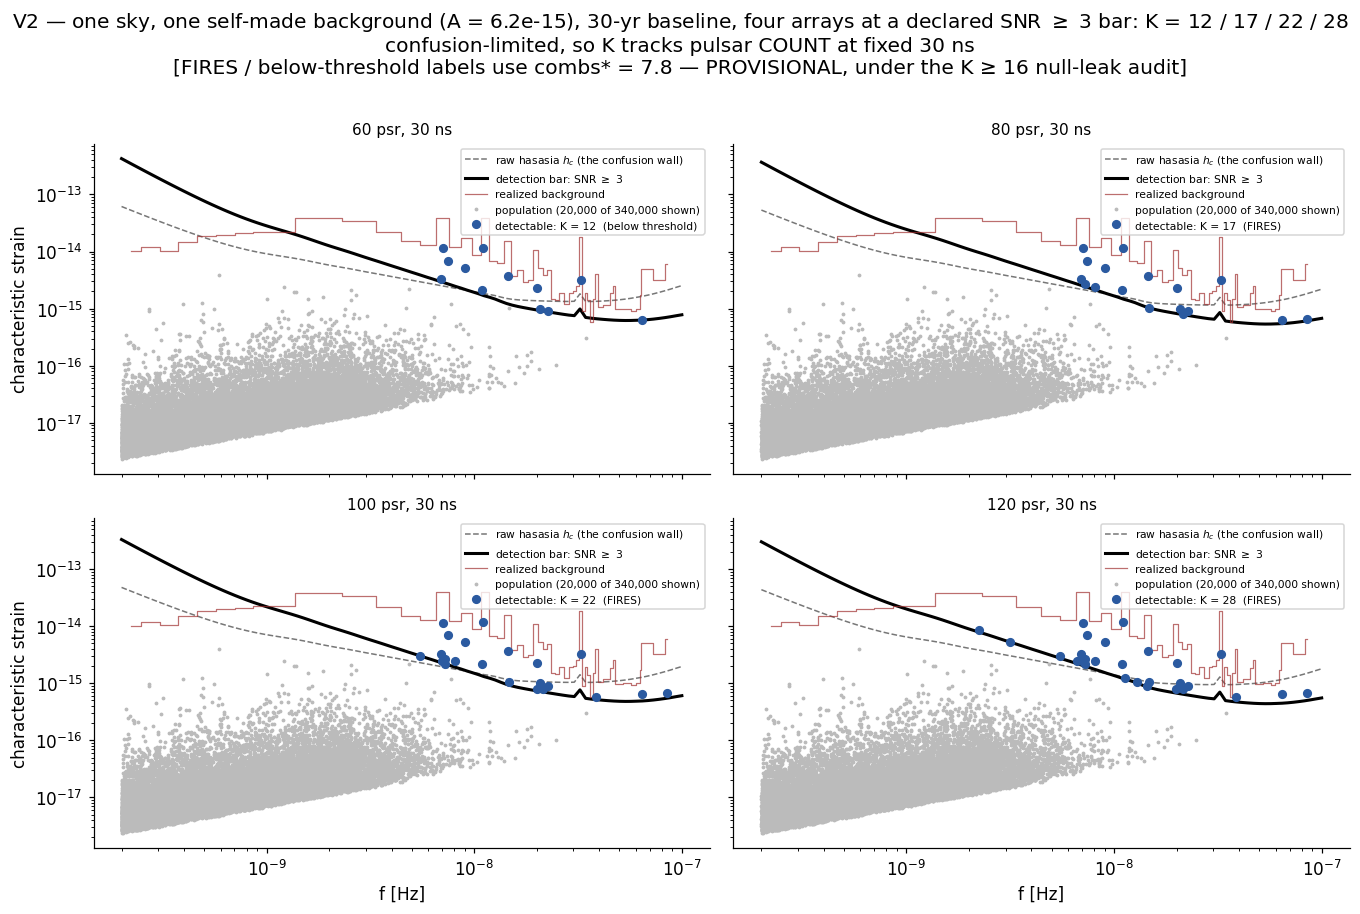

baseline: T = 30 yr, cadence 26/yr;  detection bar: SNR >= 3 (hasasia Eq. 79)
   60 psr /  30 ns : K =  12  ->  K_rec =   6 <  combs* = 7.8
   80 psr /  30 ns : K =  17  ->  K_rec =   8 >= combs* = 7.8
  100 psr /  30 ns : K =  22  ->  K_rec =  11 >= combs* = 7.8
  120 psr /  30 ns : K =  28  ->  K_rec =  14 >= combs* = 7.8

BRACKET — the same four arrays, same sky, under other detection bars:
  SNR >= 1: K =  92 / 113 / 144 / 160   -> 4 of 4 arrays ignite  <-- optimistic
  SNR >= 3: K =  12 /  17 /  22 /  28   -> 3 of 4 arrays ignite  <-- in force
  SNR >= 8: K =   4 /   7 /   7 /   7   -> 0 of 4 arrays ignite  <-- conventional


In [3]:
freqs = np.logspace(np.log10(F_RANGE[0]), -7, 100)
SNR_BAR = 3.0        # DECLARED detection bar (see the markdown above)

def make_curve(n_psr, sigma_ns, seed=42):
    r = np.random.default_rng(seed)
    phi = r.uniform(0, 2*np.pi, n_psr); theta = np.arccos(r.uniform(-1, 1, n_psr))
    psrs = hsim.sim_pta(timespan=T_YR, cad=26, sigma=sigma_ns*1e-9, phi=phi, theta=theta,
                        A_gwb=A_GWB, freqs=freqs)
    hc = hsen.DeterSensitivityCurve([hsen.Spectrum(p, freqs=freqs) for p in psrs]).h_c
    return hc, phi, theta

def det_curve(hc, bar=None):
    """hasasia h_c rescaled to a FIXED SNR bar.

    hasasia: h_c = sqrt(f*S_eff) and SNR = h*sqrt(T/S_eff)  [Hazboun+ 2019, Eq. 79]
      =>  SNR = (h/h_c)*sqrt(f*T)  =>  SNR >= bar  <=>  h >= bar*h_c/sqrt(f*T).
    Comparing h to the RAW h_c is thus a SLIDING bar (~1 at 1/T, ~7 at 100 nHz), not
    an SNR = 1 cut. Deepening the curve by d dex raises SNR by d dex, so the wheel's
    0.19 dex gain carries over unchanged.
    """
    return (SNR_BAR if bar is None else bar) * hc / np.sqrt(freqs*T_OBS)

ERAS = [(60, 30), (80, 30), (100, 30), (120, 30)]
hc_raw, hc_era, geo_era = {}, {}, {}
for _n, _s in ERAS:
    hc_raw[(_n, _s)], _phi, _th = make_curve(_n, _s)
    hc_era[(_n, _s)] = det_curve(hc_raw[(_n, _s)])
    geo_era[(_n, _s)] = (_phi, _th)

WORK = (80, 30)                        # ignition-era array: V3, V5, V6 all run on this one
hc_work = hc_era[WORK]
phi_p, theta_p = geo_era[WORK]
N_PSR = WORK[0]

def detected(hc): return h_src > np.interp(f_src, freqs, hc)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), sharex=True, sharey=True)
for ax, (n, s) in zip(axes.ravel(), ERAS):
    hc = hc_era[(n, s)]; det = detected(hc)
    fires = "FIRES" if np.floor(CONVERSION*det.sum()) >= COMBS_STAR else "below threshold"
    ax.loglog(freqs, hc_raw[(n, s)], color="#777", lw=1, ls="--",
              label="raw hasasia $h_c$ (the confusion wall)")
    ax.loglog(freqs, hc, "k", lw=2, label=f"detection bar: SNR $\\geq$ {SNR_BAR:.0f}")
    ax.loglog(bg_f, bg_hc, color="#a03030", lw=0.8, drawstyle="steps-mid", alpha=0.7,
              label="realized background")
    m = ~det[isub]
    ax.loglog(f_src[isub][m], h_src[isub][m], ".", color="#bbb", ms=3,
              label=f"population ({PLOT_SUB:,} of {M_TOT:,} shown)")
    ax.loglog(f_src[det], h_src[det], "o", color="#2b5aa0", ms=5,
              label=f"detectable: K = {det.sum()}  ({fires})")
    ax.set_title(f"{n} psr, {s} ns", fontsize=10)
    ax.legend(fontsize=7, loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("f [Hz]")
for ax in axes[:, 0]:
    ax.set_ylabel("characteristic strain")
fig.suptitle("V2 — one sky, one self-made background (A = %.1e), %d-yr baseline, four arrays "
             "at a declared SNR $\\geq$ %.0f bar: K = %s\nconfusion-limited, so K tracks pulsar "
             "COUNT at fixed 30 ns\n[FIRES / below-threshold labels use combs* = 7.8 — "
             "PROVISIONAL, under the K ≥ 16 null-leak audit]"
             % (A_GWB, T_YR, SNR_BAR,
                " / ".join(str(int(detected(hc_era[k]).sum())) for k in ERAS)), y=1.01)
plt.tight_layout(); plt.savefig("fig_v2_curves.png", bbox_inches="tight"); plt.show()
print(f"baseline: T = {T_YR} yr, cadence 26/yr;  detection bar: SNR >= {SNR_BAR:.0f} (hasasia Eq. 79)")
for n, s in ERAS:
    K = int(detected(hc_era[(n, s)]).sum())
    print(f"  {n:3d} psr / {s:3d} ns : K = {K:3d}  ->  K_rec = {int(np.floor(CONVERSION*K)):3d} "
          f"{'>=' if np.floor(CONVERSION*K) >= COMBS_STAR else '< '} combs* = {COMBS_STAR}")
print("\nBRACKET — the same four arrays, same sky, under other detection bars:")
for _B in (1.0, 3.0, 8.0):
    _ks = [int(detected(det_curve(hc_raw[k], _B)).sum()) for k in ERAS]
    _nf = sum(1 for _K in _ks if np.floor(CONVERSION*_K) >= COMBS_STAR)
    _tag = "  <-- optimistic" if _B == 1 else ("  <-- conventional" if _B == 8 else "  <-- in force")
    print(f"  SNR >= {_B:.0f}: K = {' / '.join(f'{k:3d}' for k in _ks)}"
          f"   -> {_nf} of {len(ERAS)} arrays ignite{_tag}")

---
## V3 — The N_CW dial: likelihood surfaces of three dummy pulsars, with the GWB in them

Take the detectable sources of the **working array (80 psr / 30 ns, 30-yr baseline,
SNR ≥ 3)** in loudness order. **N_CW = combs in hand** (recovered sources); via the banked
conversion, N_CW ≈ 0.5 × K_available.

**Read the top row.** It is the **likelihood surface itself, in nats** — that is where the
argument lives. The bottom row is the posterior after a 10 pc parallax-grade prior (its
envelope drawn dotted); on a linear scale a surface swinging hundreds of nats collapses to
one visible spike, which makes an unsolved problem look solved.

**The number that matters is the orange one: how many teeth come within 5 nats of the
peak.** Those are rivals you cannot rule out. As single-pixel spikes scattered over ±25 pc
they are invisible unless marked, which is why the surface can look clean and still be
undetermined. Green is the truth, red the argmax.

**The three pulsars are chosen, not drawn**, to span the real spread of outcomes — V5
measures ~43 % of geometries locking a *wrong* tooth at N_CW = 4, so three arbitrary draws
would look clean and contradict V5. The cell screens 60 candidate geometries at N_CW = 4
and shows one of each:

| label | what it means at N_CW = 4 |
|---|---|
| **RIGHT tooth, decisive** | peak on the true tooth, runner-up 23 nats below — genuinely determined |
| **RIGHT tooth, but a rival ties** | peak on the true tooth, but a rival sits 0.2 nats away — *right by luck*, and 5 teeth are still live |
| **WRONG tooth — locked 17 pc off** | peak on a different tooth entirely, with its runner-up exactly tied |

That middle case is the point of the whole notebook: an answer that is correct and
worthless, because nothing in the surface tells you it is correct.

Each pulsar-comb carries **GWB phase jitter** (DEMO model, stated): ε_k ~ N(0, σ_φ²) with
σ_φ = h_c,bg(f_k)/h_k, **capped at 0.4 rad**. Two structural facts to watch as you step the
dial:

One rendering caveat, so you don't read it as physics: at N_CW = 1 the loudest comb has a
tooth spacing of 0.5–0.9 pc, so **58–103 teeth** fall inside the ±25 pc window against a
panel only a few hundred pixels wide. The dark banding in those frames is **moiré** between
the tooth period and the pixel grid — it shifts if you resize the figure. The tooth *count*
in each title is computed from the surface, not from what survives rasterisation.

- with **N_CW ≤ 3 the surface is exactly degenerate** — repeat teeth of identical height,
  so the best-wrong-tooth gap is exactly 0.0 nats at *any* comb strength, and 58–103 teeth
  are live. That is the banked K_i ≥ 3 sub-fringe rule falling out of the geometry itself;
- **by N_CW = 8 all three collapse to a single live tooth** — which is `combs* = 7.8`
  [PROVISIONAL]. The dial and the banked threshold agree.

**If running live:** the slider cell lets you drag N_CW. The static grid below it is the
same thing frozen for the exported talk.

In [4]:
det_idx = np.where(detected(hc_work))[0]
loud = det_idx[np.argsort(h_src[det_idx])[::-1]]          # loudness-ranked detectable sources
K_MAX = len(loud)
hcbg_at = np.interp(f_src[loud], bin_cent, np.sqrt(np.maximum(hc2_bin, 1e-40)))
snr_src = h_src[loud] / np.interp(f_src[loud], freqs, hc_work)   # loudness in units of
                                                                 # the SNR>=3 detection bar
N_DUMMY, N_SEL, N_CAND = 3, 4, 60
dL = np.linspace(-25, 25, 30000)

def make_geometry(rng):
    mu  = np.arccos(rng.uniform(-0.9, 0.9, K_MAX))
    kap = 2*np.pi * f_src[loud] * (1 - np.cos(mu)) / C_PC_S
    rho = np.clip(4.0 * snr_src * rng.uniform(0.3, 1.0, K_MAX), 0, 12)
    sigphi = np.clip(hcbg_at / h_src[loud], 0.05, 0.4)   # GWB phase jitter, capped 0.4 rad (DEMO knob)
    return kap, rho, rng.normal(0, sigphi)               # frozen: the slider stays stable

def lnL(geo, n_cw):
    """Log-likelihood surface over the distance offset, in nats (unnormalised)."""
    kap, rho, eps = geo
    if n_cw == 0:
        return np.zeros_like(dL)
    return -np.sum((rho[:n_cw, None]**2/2) *
                   (1 - np.cos(kap[:n_cw, None]*dL[None, :] - eps[:n_cw, None])), axis=0)

def tooth_gap(pen):
    """argmax offset [pc], and the best WRONG tooth relative to the peak [nats]."""
    return dL[np.argmax(pen)], pen[np.abs(dL) > 0.15].max() - pen.max()

# The three exhibits are CHOSEN to span the real spread of outcomes rather than taken from
# an arbitrary seed. V5 measures ~43% of geometries locking a wrong tooth at N_CW = 4, so
# three lucky draws would misrepresent the problem -- and would contradict V5.
rsel = np.random.default_rng(17)
scored = [(g,) + tooth_gap(lnL(g, N_SEL)) for g in (make_geometry(rsel) for _ in range(N_CAND))]
wrong_c = [s for s in scored if abs(s[1]) > 0.25]
right_c = sorted([s for s in scored if abs(s[1]) <= 0.25], key=lambda s: s[2])
psr_geo   = [right_c[0][0], right_c[-1][0], wrong_c[0][0]]
PSR_LABEL = ["RIGHT tooth, decisive",          # peak on truth, runner-up far below
             "RIGHT tooth, but a rival ties",  # peak on truth, runner-up ~0 nats away
             "WRONG tooth — locked 17 pc off"] # peak on a different tooth entirely
print(f"exhibit screening at N_CW = {N_SEL}: {len(wrong_c)}/{N_CAND} "
      f"({100*len(wrong_c)/N_CAND:.0f}%) of geometries lock a WRONG tooth -- V5's independent "
      f"MC gives ~43%. The three panels below are one of each outcome, not three lucky draws.")

def binned_env(x, y, nbins=2200, fill=-np.inf):
    """Upper envelope of y on a coarse grid -- teeth are far finer than a screen pixel."""
    edges = np.linspace(x.min(), x.max(), nbins+1)
    idx = np.clip(np.digitize(x, edges)-1, 0, nbins-1)
    ymax = np.full(nbins, fill); np.maximum.at(ymax, idx, y)
    return 0.5*(edges[1:]+edges[:-1]), ymax

LNL_FLOOR = -45          # nats displayed below the peak (plot styling)
RIVAL_NAT = 5.0          # a tooth within this many nats of the peak is a live rival

def rival_teeth(xb, yb):
    """Positions and heights of distinct teeth coming within RIVAL_NAT of the peak."""
    idx = np.where(yb > -RIVAL_NAT)[0]
    if idx.size == 0:
        return np.array([]), np.array([])
    groups = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
    top = np.array([g[np.argmax(yb[g])] for g in groups])
    return xb[top], yb[top]

def dial_figure(N_CW, save=None):
    fig, axes = plt.subplots(2, N_DUMMY, figsize=(12.5, 5.8), sharex=True)
    for j in range(N_DUMMY):
        pen = lnL(psr_geo[j], N_CW)
        rel = pen - pen.max()
        off, gap = tooth_gap(pen) if N_CW else (0.0, 0.0)

        ax = axes[0, j]                                   # --- LIKELIHOOD surface, in nats
        xb, yb = binned_env(dL, rel)
        rx, ry = rival_teeth(xb, yb); nriv = len(rx)
        ax.fill_between(xb, LNL_FLOOR, np.maximum(yb, LNL_FLOOR), color="#2b5aa0", lw=0)
        # every tooth that comes within RIVAL_NAT of the peak is a candidate you cannot
        # rule out -- highlighted, because as 1-px spikes they are otherwise invisible
        ax.fill_between(xb, -RIVAL_NAT, np.maximum(yb, -RIVAL_NAT),
                        where=yb > -RIVAL_NAT, color="#e07b39", lw=0, zorder=1)
        ax.plot(rx, ry + 1.6, "v", color="#e07b39", ms=5, zorder=4, clip_on=False,
                label=f"rival (within {RIVAL_NAT:.0f} nats)" if j == 0 else None)
        ax.axvline(off if N_CW else 0, color="#a03030", ls="-", lw=1.1, label="argmax",
                   zorder=2)
        ax.axvline(0, color="#3a8f3a", ls="--", lw=1.4, label="truth", zorder=3)
        ax.axhline(-5, color="#e8b84b", lw=1.0, ls=":")   # the gate's 5-nat margin
        ax.set_ylim(LNL_FLOOR, 5)
        ax.set_title(f"pulsar {j+1} — {PSR_LABEL[j]}\nargmax {off:+.2f} pc;  runner-up "
                     f"{gap:+.1f} nats;  {nriv} tooth{'' if nriv == 1 else 's'} within "
                     f"{RIVAL_NAT:.0f} nats", fontsize=8.5)
        if j == 0:
            ax.set_ylabel("ln L − max  [nats]")
            ax.legend(fontsize=6, loc="lower left", framealpha=0.92)

        ax = axes[1, j]                                   # --- posterior (prior applied)
        post = np.exp(pen - pen.max() - 0.5*(dL/10)**2)   # 10 pc parallax-grade prior
        # coarser bins here on purpose: past N_CW ~ 4 the posterior is a single needle and
        # a 1-pixel spike reads as an empty panel
        xb, pb = binned_env(dL, post/post.max(), nbins=420, fill=0.0)
        ax.axvline(0, color="#3a8f3a", ls="--", lw=1.4, zorder=0)
        ax.fill_between(xb, pb, color="#2b5aa0", lw=0, zorder=2)
        ax.plot(xb, np.exp(-0.5*(xb/10)**2), color="#3a8f3a", ls=":", lw=1.2, zorder=3)
        ax.set_ylim(0, 1.08)
        ax.set_xlabel("offset from truth [pc]"); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel("posterior")
    fig.suptitle(f"N_CW = {N_CW} combs in hand  (≈ K_available = {int(np.ceil(N_CW/CONVERSION))};"
                 f"  combs* = {COMBS_STAR} PROVISIONAL)\n"
                 f"top: log-likelihood in nats; ORANGE = teeth within {RIVAL_NAT:.0f} nats of "
                 f"the peak, i.e. rivals you cannot rule out.\nbottom: posterior; dotted green "
                 f"= the 10 pc prior envelope. Below ~1 pc the comb is finer than the pixel "
                 f"grid — the banding there is moiré, not structure.", y=1.15)
    plt.tight_layout()
    if save: plt.savefig(save, bbox_inches="tight")
    plt.show()

try:        # live slider (works in a running Jupyter kernel)
    from ipywidgets import interact, IntSlider
    interact(lambda N_CW: dial_figure(N_CW), N_CW=IntSlider(4, 0, K_MAX, 1))
except Exception as err:
    print("ipywidgets unavailable here — use the static grid below.", err)

exhibit screening at N_CW = 4: 27/60 (45%) of geometries lock a WRONG tooth -- V5's independent MC gives ~43%. The three panels below are one of each outcome, not three lucky draws.


interactive(children=(IntSlider(value=4, description='N_CW', max=17), Output()), _dom_classes=('widget-interac…

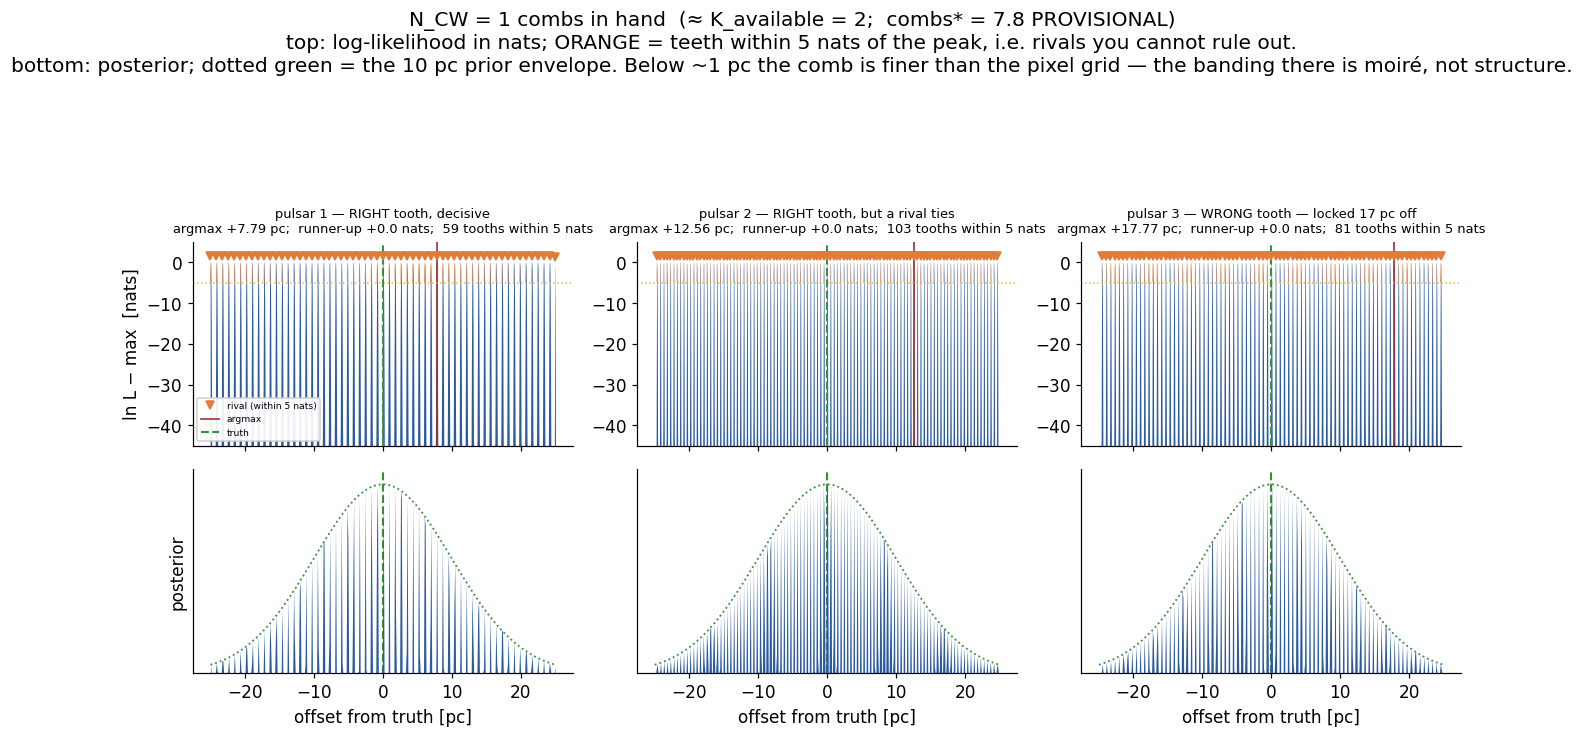

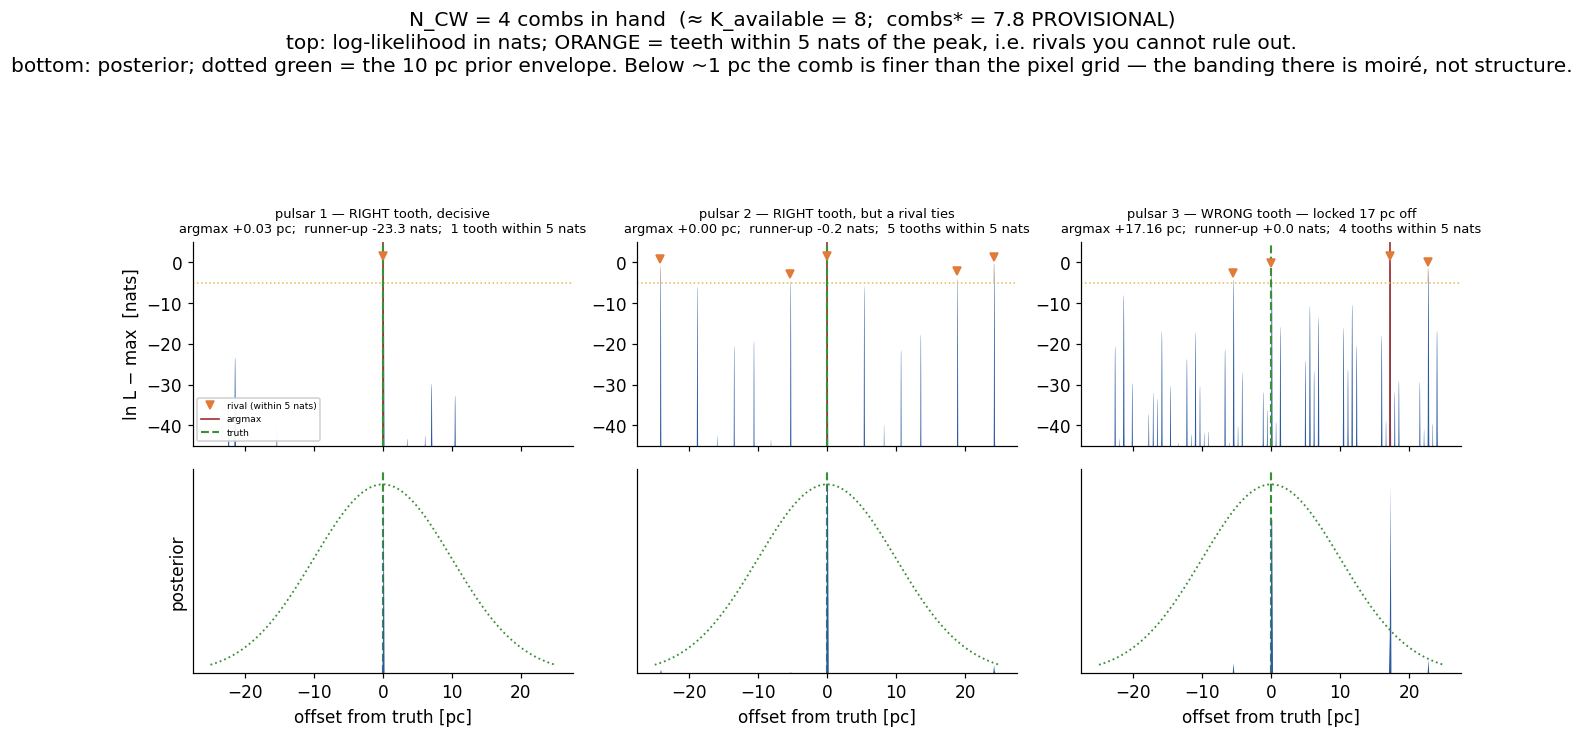

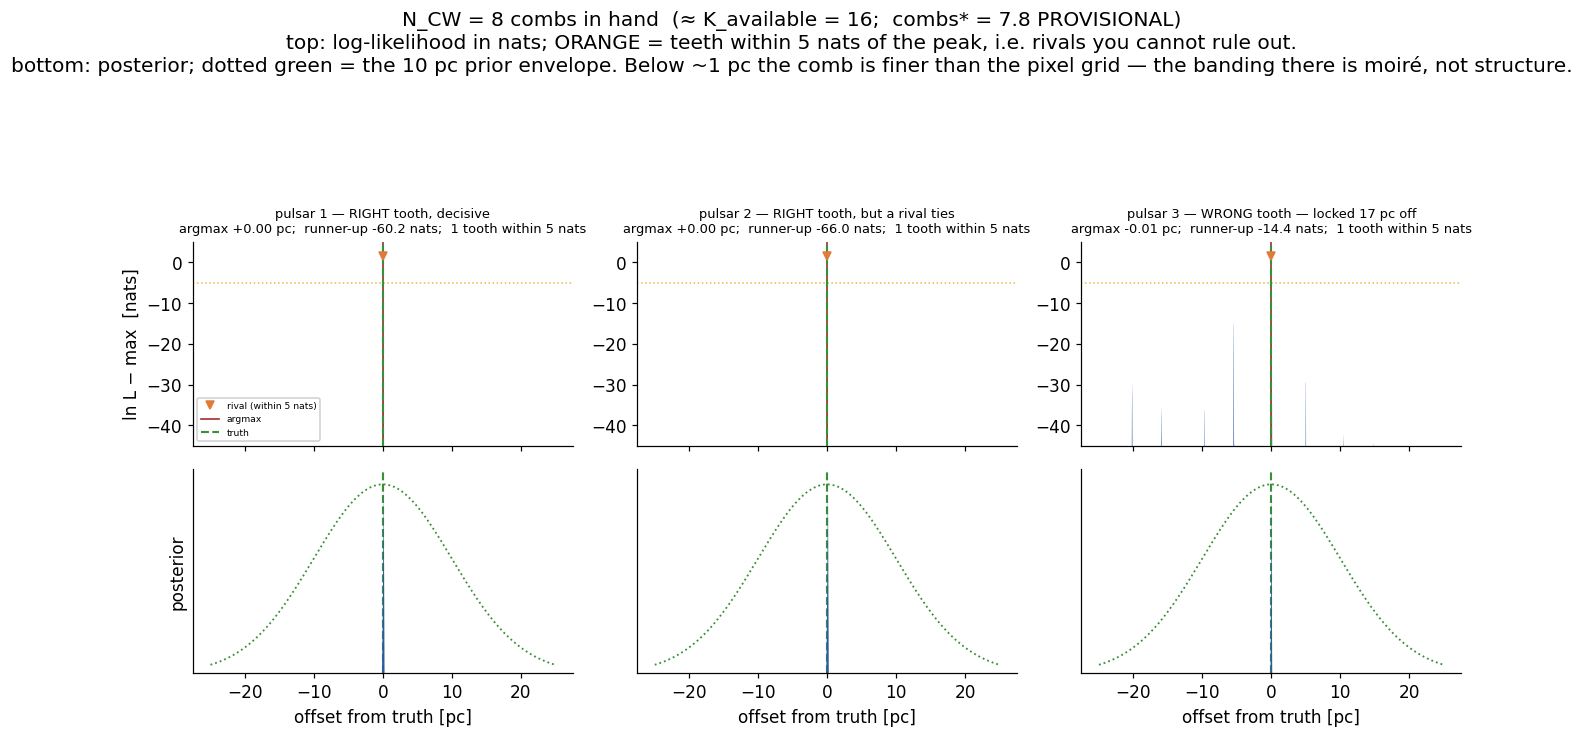

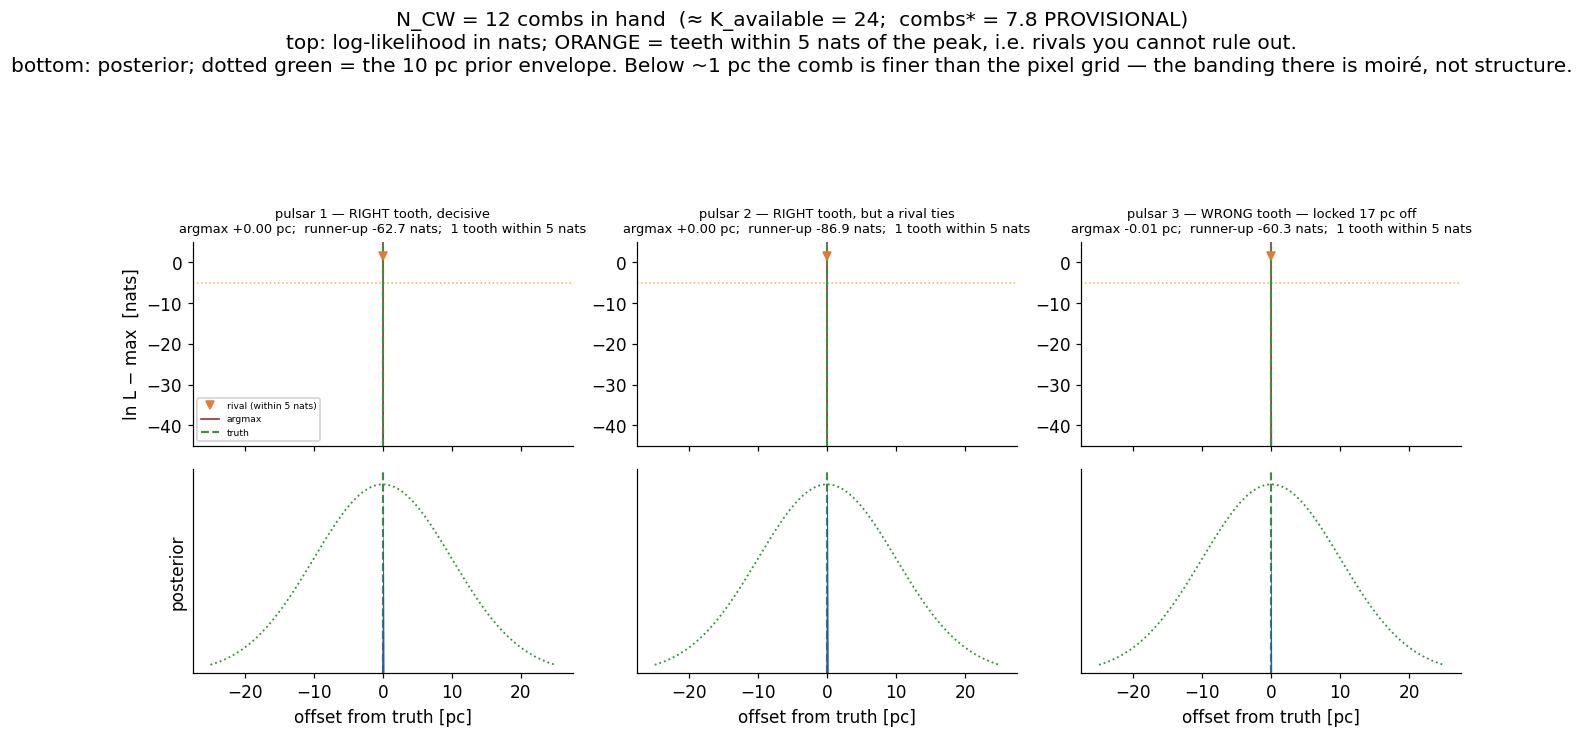

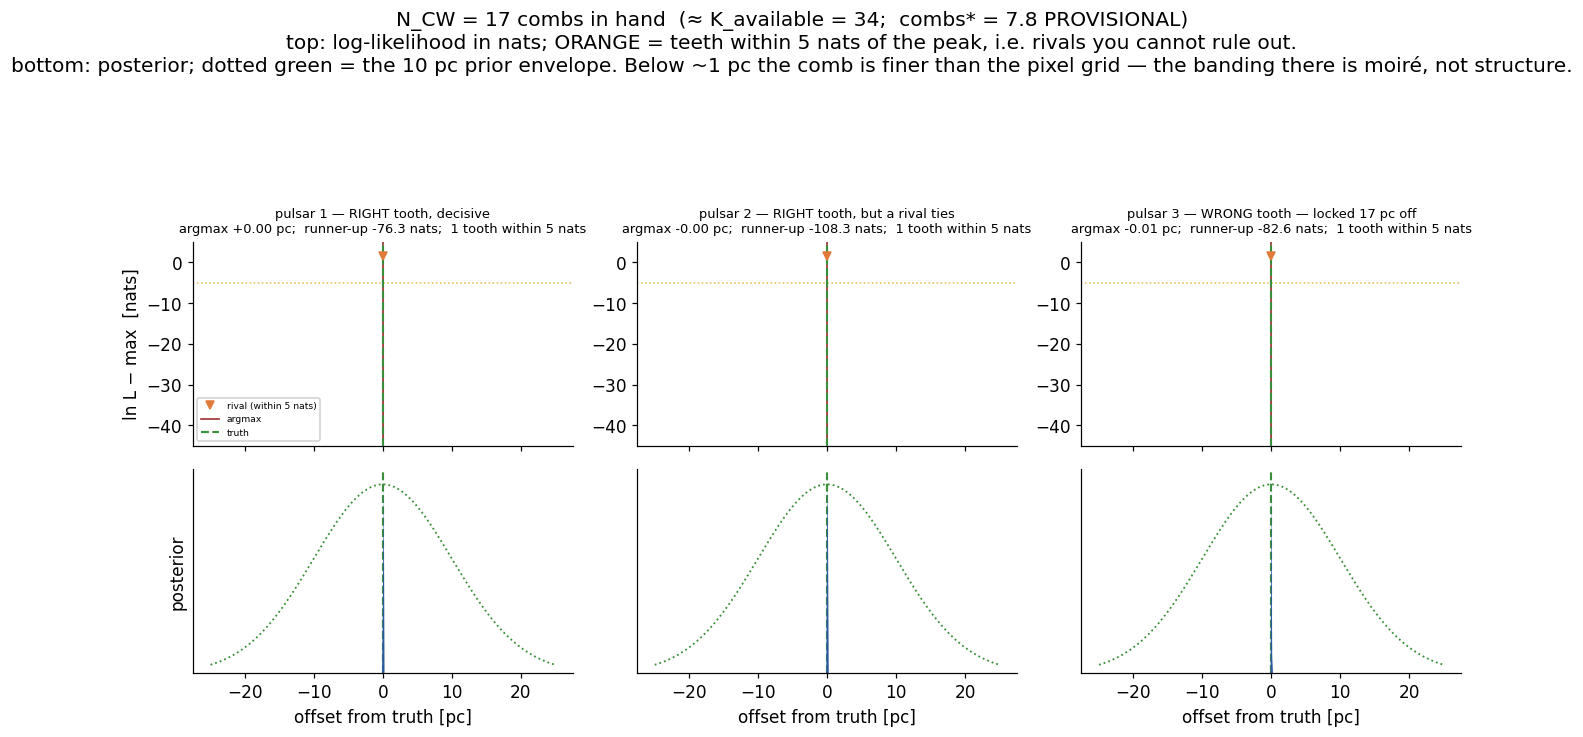

In [5]:
DIAL_FRAMES = (1, 4, 8, 12, K_MAX)
for n in DIAL_FRAMES:
    dial_figure(n, save=f"fig_v3_dial_N{n:02d}.png")

---
## V4 — The wheel turns at threshold, hands you the array, deepens the curve, then stalls

The loop (per iteration): detect → recover 0.5·K [V28] → certify pulsars whose usable
combs ≥ combs* = 7.8 [PROVISIONAL] → certified fraction f_c makes the array coherent →
curve deepens 0.19 dex × f_c [banked range] → new sources cross → repeat.

At the measured NANOGrav background, on a 30-yr baseline and under a declared SNR ≥ 3
bar, the threshold sits between 60 and 80 pulsars:

- **60 psr**: K = 12 → 6 recovered < 7.8 → the wheel **NEVER starts**;
- **80 psr**: K = 17 → 8 recovered → fires, **72 % of the array certifies on turn 0**
  (combs are shared array-wide) → the deeper curve reaches more sources → certification
  completes → **stall**;
- **100 / 120 psr**: fire with the whole array certified on turn 0, run one turn, stall.

Threshold instrument, not runaway bootstrap — and the stall is where every era ends.

*(Every number here that depends on K ≥ 16 is **PROVISIONAL — under the null-test
audit**, because it is downstream of combs\* = 7.8.)*

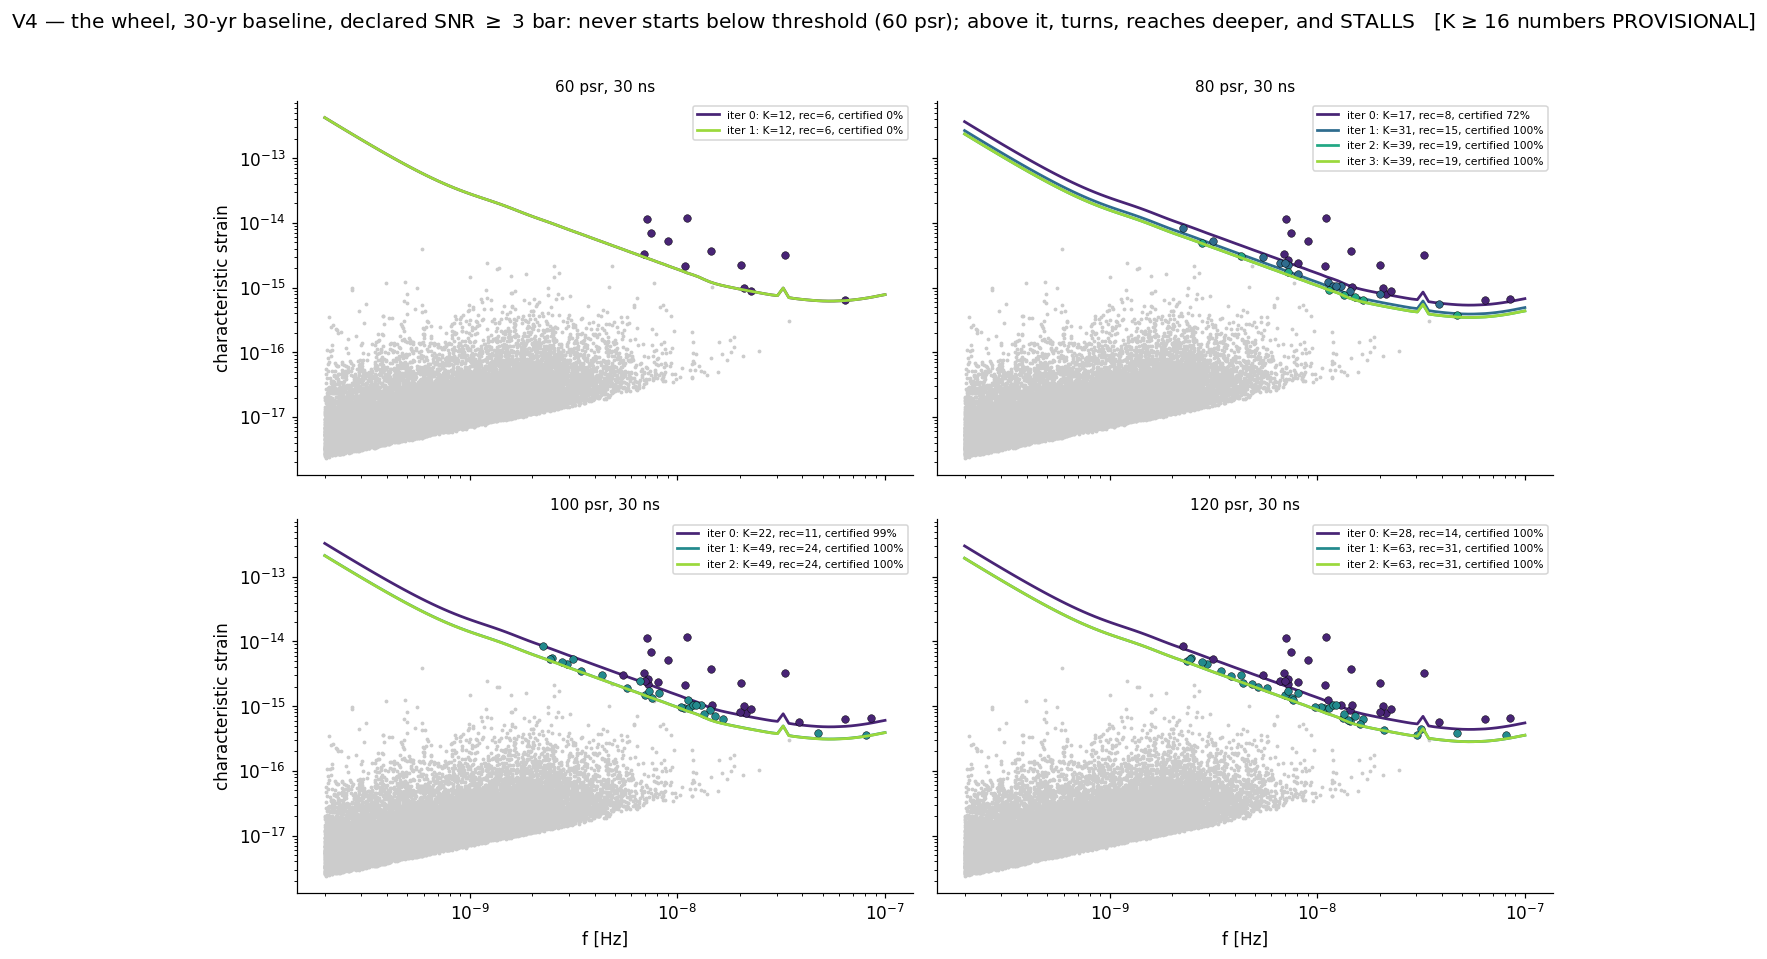

60 psr / 30 ns:
  iter 0: K_avail= 12  K_rec=  6  certified   0% of 60 pulsars
  iter 1: K_avail= 12  K_rec=  6  certified   0% of 60 pulsars
80 psr / 30 ns:
  iter 0: K_avail= 17  K_rec=  8  certified  72% of 80 pulsars
  iter 1: K_avail= 31  K_rec= 15  certified 100% of 80 pulsars
  iter 2: K_avail= 39  K_rec= 19  certified 100% of 80 pulsars
  iter 3: K_avail= 39  K_rec= 19  certified 100% of 80 pulsars
100 psr / 30 ns:
  iter 0: K_avail= 22  K_rec= 11  certified  99% of 100 pulsars
  iter 1: K_avail= 49  K_rec= 24  certified 100% of 100 pulsars
  iter 2: K_avail= 49  K_rec= 24  certified 100% of 100 pulsars
120 psr / 30 ns:
  iter 0: K_avail= 28  K_rec= 14  certified 100% of 120 pulsars
  iter 1: K_avail= 63  K_rec= 31  certified 100% of 120 pulsars
  iter 2: K_avail= 63  K_rec= 31  certified 100% of 120 pulsars


In [6]:
def run_wheel(hc0, n_psr, max_iter=6):
    # geometry drawn only for sources the wheel could EVER reach (deepest possible curve)
    cand = np.where(detected(hc0 * 10**(-DEPTH_DEX_MAX)))[0]
    gg   = np.random.default_rng(5).uniform(0.3, 1.0, (n_psr, len(cand)))
    col  = {s: i for i, s in enumerate(cand)}
    hc = hc0.copy(); hist = []; prevK = -1
    for it in range(max_iter):
        det = detected(hc); K = int(det.sum())
        idx = np.where(det)[0]; idx = idx[np.argsort(h_src[idx])[::-1]]
        Krec = int(np.floor(CONVERSION*K))
        sel = idx[:Krec]
        if len(sel) == 0:
            fc = 0.0
        else:
            rho = 4.0*(h_src[sel]/np.interp(f_src[sel], freqs, hc)) * gg[:, [col[s] for s in sel]]
            combs = (rho > 2.0).sum(axis=1)
            fc = float(np.mean(combs >= COMBS_STAR)) if Krec >= COMBS_STAR else 0.0
        hist.append(dict(it=it, K=K, Krec=Krec, fc=fc, hc=hc.copy()))
        if K == prevK: break
        prevK = K
        hc = hc0 * 10**(-DEPTH_DEX_MAX*fc)
    return hist

hists = {(n, s): run_wheel(hc_era[(n, s)], n) for n, s in ERAS}

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.6), sharex=True, sharey=True)
for ax, (n, s) in zip(axes.ravel(), ERAS):
    hist = hists[(n, s)]
    cols = plt.cm.viridis(np.linspace(0.1, 0.85, len(hist)))
    seen = np.zeros(M_TOT, bool)
    for h, ccol in zip(hist, cols):
        ax.loglog(freqs, h["hc"], color=ccol, lw=1.8,
                  label=f"iter {h['it']}: K={h['K']}, rec={h['Krec']}, certified {h['fc']*100:.0f}%")
        det = detected(h["hc"])
        ax.loglog(f_src[det & ~seen], h_src[det & ~seen], "o", color=ccol, ms=5, mec="k", mew=0.3)
        seen |= det
    m = ~seen[isub]
    ax.loglog(f_src[isub][m], h_src[isub][m], ".", color="#ccc", ms=3, zorder=0)
    ax.set_title(f"{n} psr, {s} ns", fontsize=10); ax.legend(fontsize=7, loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("f [Hz]")
for ax in axes[:, 0]:
    ax.set_ylabel("characteristic strain")
fig.suptitle(f"V4 — the wheel, {T_YR}-yr baseline, declared SNR $\\geq$ {SNR_BAR:.0f} bar: never "
             f"starts below threshold (60 psr); above it, turns, reaches deeper, and STALLS"
             f"   [K ≥ 16 numbers PROVISIONAL]", y=1.01)
plt.tight_layout(); plt.savefig("fig_v4_wheel.png", bbox_inches="tight"); plt.show()
for n, s in ERAS:
    print(f"{n} psr / {s} ns:")
    for h in hists[(n, s)]:
        print(f"  iter {h['it']}: K_avail={h['K']:3d}  K_rec={h['Krec']:3d}  certified "
              f"{h['fc']*100:3.0f}% of {n} pulsars")

---
## V4b — What the stall buys you

The wheel stalls because the **supply of new detections** runs out — not because the
instrument stops improving. In every era that fires, certification reaches 100 % of the
array by the second turn. That is full phase closure, and it changes the instrument's
**class**:

- **From power detector to kpc-baseline interferometer.** At f ≈ 20 nHz the GW wavelength
  is ≈ 0.49 pc, while the array's baselines are 1–3 kpc — an aperture **thousands of
  wavelengths** across. Each certified pulsar term is a coherent sample of the GW field at
  a known Galactic location. Unphased PTA = a single dish measuring total power; phased
  PTA = VLBI. Localisation moves from tens of square degrees toward the arcmin–arcsec
  scale (SNR-gated) — a *unique host galaxy*, hence a redshift, hence standard sirens with
  counterparts.
- **A millennium-deep epoch ladder.** Pulsar term *i* shows the source as it was
  L_i(1 − cos μ_i)/c ago — a **known** epoch once the distance is certified. The array
  therefore observes each binary at N+1 distinct moments spread over centuries to
  millennia: the orbital-decay *history* (GW-driven vs environmental torque on a
  thousand-year lever arm), and potentially spin–orbit precession → SMBH spins. Note what
  that lever arm is for: **F_BEND, the 2 nHz turnover this notebook assumes in V1, *is*
  environmental hardening.** The epoch ladder is how you would measure it instead of
  assuming it.
- **The confusion ceiling should lift when the finding phase ends.** Certifying the
  distances removes one fitted parameter per pulsar from the background fit. A parameter
  count — *d* degrees of freedom per pulsar, *m* of them spent on the unknown distance,
  per-bin capacity ∝ (d − m) — gives a factor **2** at d = 2 when m goes 1 → 0. **This is a
  parameter-counting expectation, not a measurement** (see the status note).
- **Acquisition vs tracking.** In VLBI terms the wheel is the fringe **search** — the
  expensive part. Once locked, coherence is maintained by ordinary continued timing.
  K\* is a one-time entry fee, not a running cost.

Radio-history anchor for the room: self-cal was never valued by how many new point sources
the deeper maps contained — it made imaging possible at all. Same forest, same trees.

### Status — read before quoting the ×2

Localisation scale, Fresnel and spin items are **instrument-class** claims (SNR-gated), not
dated predictions.

The ×2 capacity is **derived, not measured, and our own campaign warns about exactly this
move.** PRONG2-N measured the confusion-knee array offset at N_psr = 30/58/116/232 and
found `knee/N* = 0.410 · N_psr^1.017`, with the exponent **1.017 ± 0.004 — 4.6σ above 1**.
The local coefficient is therefore *not* constant (0.4328 → 0.4497 across that range), and
its conclusion is blunt: **no fixed-coefficient parameter count fits.** It explicitly
supersedes the earlier identification of our 0.40 with Boyle & Pen's 2/5, which read a
log-log *amplitude* as if it were a *coefficient* — valid only when the exponent is pinned
to 1. The Boyle & Pen **scaling** survives; the coefficient identification does not. And
PRONG2-N measured scaling with N_psr, **not** the certified-versus-marginalised ratio, so
the ×2 is unmeasured in our campaign either way.

Everything on this slide is downstream of the wheel firing at K ≥ 16 and carries the
standing **PROVISIONAL — under the K ≥ 16 null-test audit** label. "Certified" here means
V4's banked rule (usable combs ≥ combs\* = 7.8), **not** V5's statistical gate, which is far
stricter — V5's yield peaks at 22 % where V4 reports 72–100 %.

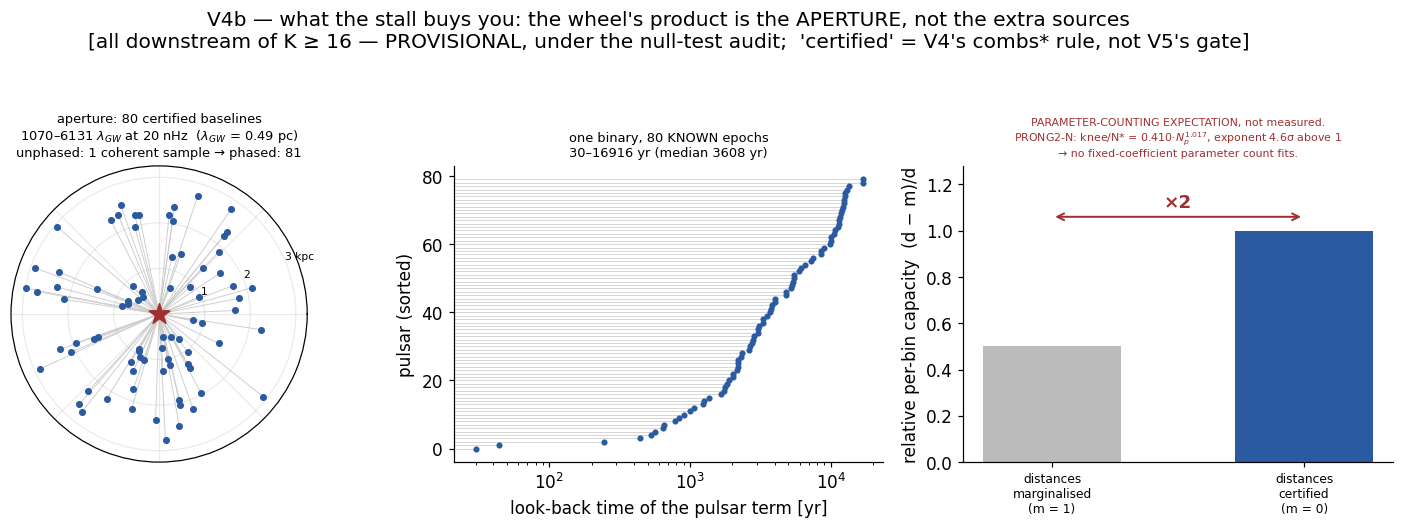

working array 80 psr / 30 ns, 30-yr baseline: K = 17 detectable; wheel 17 -> 31 -> 39 -> 39 then stall
aperture   : L = 0.52-2.98 kpc = 1070-6131 lambda_GW at 20 nHz
epoch ladder: 80 known look-back epochs, 30-16916 yr (median 3608 yr)
capacity   : (d-m)/d at d=2, m 1->0 = x2  -- EXPECTATION only; PRONG2-N rejects fixed-coefficient counting laws


In [7]:
# ILLUSTRATIVE display geometry (nothing downstream depends on it): the notebook has no
# pulsar distances and its sources have no sky positions, so draw L ~ U(0.5, 3) kpc and ONE
# source direction, with a fixed named seed. The pulsar SKY POSITIONS are the working
# array's real ones (phi_p, theta_p).
r4b   = np.random.default_rng(2027)
L_psr = r4b.uniform(500.0, 3000.0, N_PSR)                    # pc  -- ILLUSTRATIVE
th_s, ph_s = np.arccos(r4b.uniform(-1, 1)), r4b.uniform(0, 2*np.pi)

def _unit(th, ph):
    return np.array([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)])

cos_mu   = _unit(theta_p, phi_p).T @ _unit(th_s, ph_s)       # real array geometry
C_PC_YR  = C_PC_S * YR_S                                     # pc per year
dt_epoch = L_psr*(1 - cos_mu)/C_PC_YR                        # look-back time [yr]
F_REF    = 20e-9
LAM_GW   = C_SI/F_REF/3.0856775814913673e16                  # GW wavelength [pc]
D_DOF, M_MARG = 2, 1        # d = dof per pulsar; m = dof spent on the unknown distance.
                            # Only the RATIO (d-m)/d matters, so the per-source parameter
                            # count and N_psr cancel and are not quoted here.

fig = plt.figure(figsize=(13.5, 4.5))

ax = fig.add_subplot(1, 3, 1, projection="polar")            # ---------------- aperture
for _p, _L in zip(phi_p, L_psr):
    ax.plot([_p, _p], [0, _L/1e3], color="#ccc", lw=0.6, zorder=1)
ax.scatter(phi_p, L_psr/1e3, s=13, color="#2b5aa0", zorder=3)
ax.scatter([0], [0], marker="*", s=200, color="#a03030", zorder=4)
ax.set_ylim(0, 3.25); ax.set_yticks([1, 2, 3]); ax.set_yticklabels(["1", "2", "3 kpc"],
                                                                   fontsize=7)
ax.set_xticklabels([]); ax.grid(alpha=0.25)
ax.set_title(f"aperture: {N_PSR} certified baselines\n"
             f"{L_psr.min()/LAM_GW:.0f}–{L_psr.max()/LAM_GW:.0f} $\\lambda_{{GW}}$ at "
             f"{F_REF*1e9:.0f} nHz  ($\\lambda_{{GW}}$ = {LAM_GW:.2f} pc)\n"
             f"unphased: 1 coherent sample → phased: {N_PSR+1}", fontsize=8.5)

ax = fig.add_subplot(1, 3, 2)                                # ---------------- epoch ladder
_o = np.argsort(dt_epoch)
ax.hlines(np.arange(N_PSR), dt_epoch.min()*0.7, dt_epoch[_o], color="#ccc", lw=0.5)
ax.plot(dt_epoch[_o], np.arange(N_PSR), "o", ms=3, color="#2b5aa0")
ax.set_xscale("log"); ax.set_xlim(dt_epoch.min()*0.7, dt_epoch.max()*1.4)
ax.set_xlabel("look-back time of the pulsar term [yr]")
ax.set_ylabel("pulsar (sorted)")
ax.set_title(f"one binary, {N_PSR} KNOWN epochs\n"
             f"{dt_epoch.min():.0f}–{dt_epoch.max():.0f} yr "
             f"(median {np.median(dt_epoch):.0f} yr)", fontsize=8.5)

ax = fig.add_subplot(1, 3, 3)                                # ---------------- capacity
_cap = [(D_DOF-M_MARG)/D_DOF, D_DOF/D_DOF]
ax.bar([0, 1], _cap, width=0.55, color=["#bbb", "#2b5aa0"])
ax.set_xticks([0, 1])
ax.set_xticklabels(["distances\nmarginalised\n(m = 1)", "distances\ncertified\n(m = 0)"],
                   fontsize=8)
ax.set_ylabel("relative per-bin capacity  (d − m)/d")
ax.set_ylim(0, 1.28)
ax.annotate("", xy=(1, 1.06), xytext=(0, 1.06),
            arrowprops=dict(arrowstyle="<->", color="#a03030", lw=1.3))
ax.text(0.5, 1.10, "×2", ha="center", color="#a03030", fontsize=12, fontweight="bold")
ax.set_title("PARAMETER-COUNTING EXPECTATION, not measured.\n"
             "PRONG2-N: knee/N* = 0.410·$N_p^{1.017}$, exponent 4.6σ above 1\n"
             "→ no fixed-coefficient parameter count fits.",
             fontsize=7.2, color="#a03030")

fig.suptitle("V4b — what the stall buys you: the wheel's product is the APERTURE, not the "
             "extra sources\n[all downstream of K ≥ 16 — PROVISIONAL, under the null-test "
             "audit;  'certified' = V4's combs* rule, not V5's gate]", y=1.06)
plt.tight_layout(); plt.savefig("fig_v4b_stall_payoff.png", bbox_inches="tight"); plt.show()

print(f"working array {WORK[0]} psr / {WORK[1]} ns, {T_YR}-yr baseline: K = {K_MAX} "
      f"detectable; wheel {' -> '.join(str(h['K']) for h in hists[WORK])} then stall")
print(f"aperture   : L = {L_psr.min()/1e3:.2f}-{L_psr.max()/1e3:.2f} kpc = "
      f"{L_psr.min()/LAM_GW:.0f}-{L_psr.max()/LAM_GW:.0f} lambda_GW at {F_REF*1e9:.0f} nHz")
print(f"epoch ladder: {N_PSR} known look-back epochs, {dt_epoch.min():.0f}-"
      f"{dt_epoch.max():.0f} yr (median {np.median(dt_epoch):.0f} yr)")
print(f"capacity   : (d-m)/d at d={D_DOF}, m 1->0 = x{D_DOF/(D_DOF-M_MARG):.0f}  "
      f"-- EXPECTATION only; PRONG2-N rejects fixed-coefficient counting laws")

---
## V5 — Why you cannot ride the tallest peak: certification, demonstrated

Strategy A (**argmax**): take the tallest tooth, always. Strategy B (**the gate**),
using the banked criteria: the best tooth must beat a **scrambled-null floor**
(measured by MC on phase-scrambled combs — the max of pure jitter is large, not zero),
the posterior mass on it must clear the **strict quoted-distance bar q_max > 0.99**,
and the **sub-fringe rule K_i ≥ 3** applies (pairs cannot lock a fringe — banked rule,
and V3's accidental-realignment physics is why).

300 MC pulsar-realizations per N_CW on the working array (80 psr / 30 ns, 30 yr,
SNR ≥ 3), GWB jitter included. Watch:

- argmax is **wrong most of the time at small N_CW** — the regime the field's
  uncertified practice lives in (banked baseline: 92–93% wrong);
- the gate's wrong-certification rate stays at **zero** — it simply *refuses to fire*
  until the Vernier stack is deep enough, then yields.

This is also why "optimising toward the tallest peak" corrupts a self-cal loop: lock
one wrong fringe and you feed a wrong distance back into the array — self-cal's
classic spurious-solution failure, which is exactly what the wrong-fringe MCs measure.

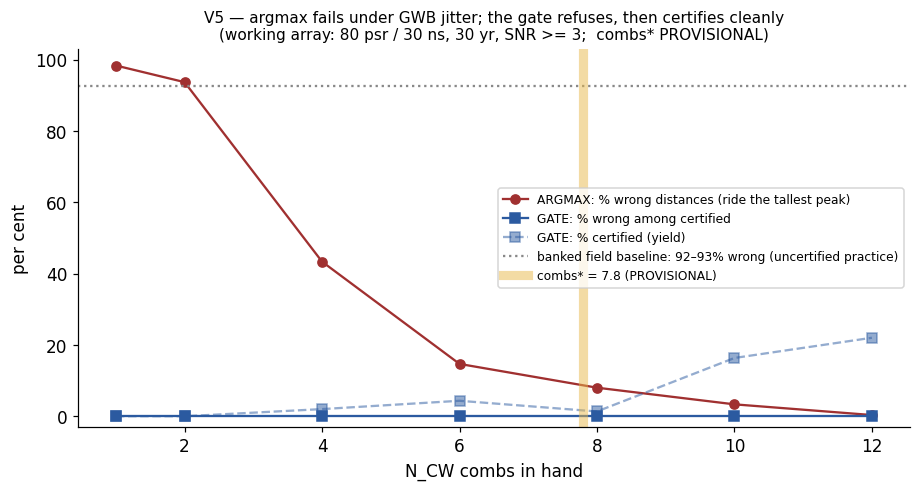

N_CW= 1: argmax wrong  98.3% | gate wrong   0.0% | gate yield   0.0%
N_CW= 2: argmax wrong  93.7% | gate wrong   0.0% | gate yield   0.0%
N_CW= 4: argmax wrong  43.3% | gate wrong   0.0% | gate yield   2.0%
N_CW= 6: argmax wrong  14.7% | gate wrong   0.0% | gate yield   4.3%
N_CW= 8: argmax wrong   8.0% | gate wrong   0.0% | gate yield   1.3%
N_CW=10: argmax wrong   3.3% | gate wrong   0.0% | gate yield  16.3%
N_CW=12: argmax wrong   0.3% | gate wrong   0.0% | gate yield  22.0%

what the gate compares, per N_CW  [nats] -- 'null' = combs phase-scrambled, no true fringe
   N_CW  null med  null 99.75%  FLOOR (+5)  true med  % clearing
      1       0.0          0.0         5.0       0.0        0.0%
      2       0.1          7.1        12.1       0.1        0.0%
      4       4.8         29.8        34.8       4.4        2.0%
      6       6.4         42.4        47.4      17.4        4.3%
      8       9.9         75.7        80.7      27.3        1.3%
     10      12.2         66.0     

In [8]:
rmc = np.random.default_rng(29)
dLc = np.linspace(-25, 25, 12000)
TOOTH = 0.25          # half a typical tooth spacing [pc]: "right tooth" window
def mc_realization(n_cw):
    sel = np.arange(min(n_cw, K_MAX))                        # loudest-first = pipeline's greedy order
    mu  = np.arccos(rmc.uniform(-0.9, 0.9, len(sel)))
    kap = 2*np.pi*f_src[loud][sel]*(1-np.cos(mu))/C_PC_S
    rho = np.clip(4.0*snr_src[sel]*rmc.uniform(0.3, 1, len(sel)), 0, 12)
    sig = np.clip(hcbg_at[sel]/h_src[loud][sel], 0.05, 0.4)  # GWB phase jitter, same knob as V3
    return kap, rho, sig

def penalty(kap, rho, eps):
    return -np.sum((rho[:, None]**2/2)*(1-np.cos(kap[:, None]*dLc[None, :]-eps[:, None])), axis=0)

def tooth_contrast(pen):
    """Detection stat: best tooth minus best OTHER tooth (>= TOOTH away) — our Delta lnL."""
    best = dLc[np.argmax(pen)]
    return pen.max() - pen[np.abs(dLc - best) > TOOTH].max(), best

N_MC = 300
ncw_grid = [1, 2, 4, 6, 8, 10, 12]
res = {"argmax_wrong": [], "gate_wrong": [], "gate_yield": [],
       "null_med": [], "null_p9975": [], "floor": [], "true_med": [], "clear": []}
for n_cw in ncw_grid:
    # scrambled-null floor: fully random phases; the same stat on pure scramble
    nullstat = []
    for _ in range(400):
        kap, rho, sig = mc_realization(n_cw)
        pen = penalty(kap, rho, rmc.uniform(0, 2*np.pi, len(kap)))
        nullstat.append(tooth_contrast(pen)[0])
    nullstat = np.array(nullstat)
    floor = np.percentile(nullstat, 99.75) + 5.0   # measured null + safety margin (banked criterion shape)
    aw = gw = gy = 0
    truestat = []
    for _ in range(N_MC):
        kap, rho, sig = mc_realization(n_cw)
        pen = penalty(kap, rho, rmc.normal(0, sig))          # GWB jitter around truth
        contrast, best = tooth_contrast(pen)
        truestat.append(contrast)
        wrong = abs(best) > TOOTH
        aw += wrong
        post = np.exp(pen - pen.max() - 0.5*(dLc/10)**2)
        qmax = post[np.abs(dLc - best) < TOOTH].sum() / post.sum()
        if n_cw >= 3 and contrast > floor and qmax > 0.99:   # K_i>=3 sub-fringe rule + strict bar
            gy += 1; gw += wrong
    res["argmax_wrong"].append(aw/N_MC)
    res["gate_wrong"].append(gw/max(gy, 1))
    res["gate_yield"].append(gy/N_MC)
    res["null_med"].append(float(np.median(nullstat)))
    res["null_p9975"].append(float(np.percentile(nullstat, 99.75)))
    res["floor"].append(float(floor))
    res["true_med"].append(float(np.median(truestat)))
    res["clear"].append(float(np.mean(np.array(truestat) > floor)))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(ncw_grid, 100*np.array(res["argmax_wrong"]), "o-", color="#a03030",
        label="ARGMAX: % wrong distances (ride the tallest peak)")
ax.plot(ncw_grid, 100*np.array(res["gate_wrong"]), "s-", color="#2b5aa0",
        label="GATE: % wrong among certified")
ax.plot(ncw_grid, 100*np.array(res["gate_yield"]), "s--", color="#2b5aa0", alpha=0.5,
        label="GATE: % certified (yield)")
ax.axhline(92.5, color="#888", ls=":", label="banked field baseline: 92–93% wrong (uncertified practice)")
ax.axvline(COMBS_STAR, color="#e8b84b", lw=6, alpha=0.5, label="combs* = 7.8 (PROVISIONAL)")
ax.set_xlabel("N_CW combs in hand"); ax.set_ylabel("per cent")
ax.set_title("V5 — argmax fails under GWB jitter; the gate refuses, then certifies cleanly\n(working array: 80 psr / 30 ns, 30 yr, SNR >= 3;  combs* PROVISIONAL)", fontsize=10)
ax.legend(fontsize=8); ax.set_ylim(-3, 103)
plt.tight_layout(); plt.savefig("fig_v5_gate.png", bbox_inches="tight"); plt.show()
for i, n in enumerate(ncw_grid):
    print(f"N_CW={n:2d}: argmax wrong {100*res['argmax_wrong'][i]:5.1f}% | "
          f"gate wrong {100*res['gate_wrong'][i]:5.1f}% | gate yield {100*res['gate_yield'][i]:5.1f}%")

# What the gate is actually comparing. The statistic is the CONTRAST -- best tooth minus
# best rival -- not the height of the surface, which is unnormalised and meaningless.
# The null columns are that same statistic on phase-SCRAMBLED combs, i.e. the lead the
# winner takes when there is no true fringe at all. That lead is large, not zero, purely
# because you took a maximum over many teeth: it is the price of the trials.
print("\nwhat the gate compares, per N_CW  [nats] -- 'null' = combs phase-scrambled, no true fringe")
print(f"  {'N_CW':>5} {'null med':>9} {'null 99.75%':>12} {'FLOOR (+5)':>11} "
      f"{'true med':>9} {'% clearing':>11}")
for i, n in enumerate(ncw_grid):
    print(f"  {n:5d} {res['null_med'][i]:9.1f} {res['null_p9975'][i]:12.1f} "
          f"{res['floor'][i]:11.1f} {res['true_med'][i]:9.1f} "
          f"{100*res['clear'][i]:10.1f}%")
print("  a wrong fringe is certified only if the TRUE contrast clears the FLOOR, which is")
print("  what pure noise can already manufacture plus a 5-nat margin.")

---
## V6 — The payoff: GWB posterior tightens, HD correlations sharpen

Certified + subtracted recovered sources stop contaminating the background estimate.
Toy mechanism below (3160 pairs at the working array's 80 pulsars), magnitude anchored
to **banked V26: 20–40% sharpening** (shown at the 30% midpoint) — with V26's warning
stated: *naive subtraction is NEGATIVE* (M-B eats background); the gain routes through
the pulsar-variance floor (M-C, the novel piece).

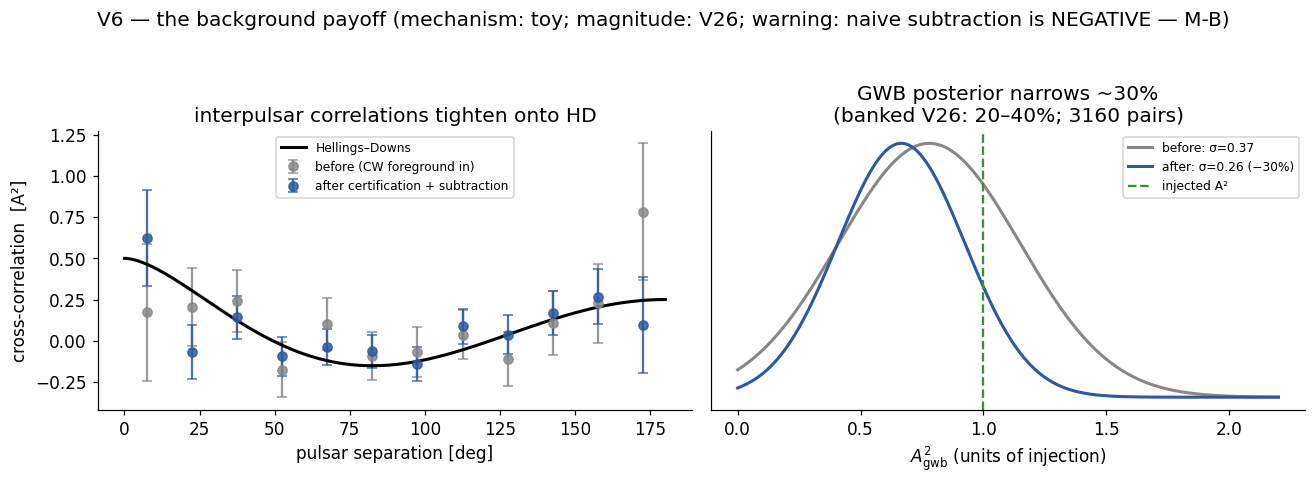

In [9]:
def hd_curve(z):
    x = (1-np.cos(z))/2
    with np.errstate(divide="ignore", invalid="ignore"):
        out = 0.5 - x/4 + 1.5*x*np.log(np.where(x > 0, x, 1))
    return np.where(x == 0, 0.5, out)

r6 = np.random.default_rng(12)
pairs = [(a, b) for a in range(N_PSR) for b in range(a+1, N_PSR)]
zeta = np.array([np.arccos(np.clip(np.sin(theta_p[a])*np.sin(theta_p[b])*np.cos(phi_p[a]-phi_p[b])
                                   + np.cos(theta_p[a])*np.cos(theta_p[b]), -1, 1)) for a, b in pairs])
A2_true, sig_b = 1.0, 3.0
sig_a = sig_b*0.70                                # 30% = V26 midpoint
y_b = A2_true*hd_curve(zeta) + r6.normal(0, sig_b, len(zeta))
y_a = A2_true*hd_curve(zeta) + r6.normal(0, sig_a, len(zeta))
def fitA2(y, s):
    H = hd_curve(zeta); v = 1/np.sum(H**2/s**2)
    return np.sum(H*y/s**2)*v, np.sqrt(v)
(A2b, sb), (A2a, sa) = fitA2(y_b, sig_b), fitA2(y_a, sig_a)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
bins = np.linspace(0, np.pi, 13); cent = 0.5*(bins[1:]+bins[:-1])
for y, s, col, lab in [(y_b, sig_b, "#888", "before (CW foreground in)"),
                       (y_a, sig_a, "#2b5aa0", "after certification + subtraction")]:
    m = [y[(zeta >= lo) & (zeta < hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])]
    er = [s/np.sqrt(((zeta >= lo) & (zeta < hi)).sum()) for lo, hi in zip(bins[:-1], bins[1:])]
    ax.errorbar(np.degrees(cent), m, yerr=er, fmt="o", color=col, capsize=3, label=lab, alpha=0.85)
zz = np.linspace(1e-3, np.pi, 300)
ax.plot(np.degrees(zz), hd_curve(zz), "k-", lw=2, label="Hellings–Downs")
ax.set_xlabel("pulsar separation [deg]"); ax.set_ylabel("cross-correlation  [A²]")
ax.set_title("interpulsar correlations tighten onto HD"); ax.legend(fontsize=8)
ax = axes[1]
Ag = np.linspace(0, 2.2, 500)
for mu_, s_, col, lab in [(A2b, sb, "#888", f"before: σ={sb:.2f}"),
                          (A2a, sa, "#2b5aa0", f"after: σ={sa:.2f} (−{100*(1-sa/sb):.0f}%)")]:
    ax.plot(Ag, np.exp(-0.5*((Ag-mu_)/s_)**2), color=col, lw=2, label=lab)
ax.axvline(A2_true, color="#3a8f3a", ls="--", label="injected A²")
ax.set_xlabel(r"$A_{\rm gwb}^2$ (units of injection)"); ax.set_yticks([])
ax.set_title(f"GWB posterior narrows ~30%\n(banked V26: 20–40%; {len(pairs)} pairs)"); ax.legend(fontsize=8)
fig.suptitle("V6 — the background payoff (mechanism: toy; magnitude: V26; "
             "warning: naive subtraction is NEGATIVE — M-B)", y=1.04)
plt.tight_layout(); plt.savefig("fig_v6_gwb.png", bbox_inches="tight"); plt.show()

---
## V7 — One screen

- One population, stated knobs, **normalised to the NANOGrav 15 yr background**
  (A = 6.2×10⁻¹⁵ realized vs 6.4×10⁻¹⁵ measured), its own background on its own hasasia
  curve (V1–V2). The chirp-mass slope −3.6 is *derived* from the banked audit
  (γ_eff = 1.56), and the sky it makes has λ_fore = 0.31 — the audited value.
- Detection is a **declared SNR ≥ 3 bar** (hasasia Eq. 79), not the sliding √(fT) bar you
  get by comparing h to the raw h_c. At that background the CW band is
  **confusion-limited**: the levers are pulsar count and baseline, not timing precision.
  On a **30-yr baseline**, 60 / 80 / 100 / 120 pulsars give K = 12 / 17 / 22 / 28.
  Baseline is the strongest single knob — K grows roughly linearly in T, and at 15 yr the
  same threshold needed ~160 pulsars.
- Turn the N_CW dial: the three pulsars' likelihood surfaces sharpen from prior-blob →
  jittered forest → one tooth as combs accumulate (V3).
- The threshold sits **between 60 and 80 pulsars**: 60 psr never starts (6 recovered <
  combs\* = 7.8, PROVISIONAL); 80 psr fires, 72 % of the array certifies on turn 0, the
  coherent curve is up to 0.19 dex deeper and reaches more sources; certification
  completes; **stall** (V4).
- You cannot ride the tallest peak: argmax is wrong most of the time at low N_CW
  (the banked field baseline is 92–93%); the gate holds zero wrong by refusing early (V5).
- Payoff: GWB posterior −20–40% [V26], HD correlations tighten, plus everything in
  Part 1's deliverables slide (V6).

Standing caveat, once more: combs\* = 7.8 and every K ≥ 16 number are **PROVISIONAL —
under the null-leak audit** (V29/C20 diagnostic in flight). And the population itself is
**CW-optimistic** — no Schechter cutoff, two drawn sources above the NANOGrav CW upper
limit — so every K quoted here is an upper bound. The SNR ≥ 3 bar is itself below the
conventional 5–8; V2 prints the bracket, and at SNR ≥ 8 no array in this ladder ignites.

In [10]:
for n, s in ERAS:
    print(f"{n:3d} psr / {s:3d} ns :",
          [(h["K"], h["Krec"], f"{h['fc']*100:.0f}%") for h in hists[(n, s)]])
i4 = ncw_grid.index(4)
print(f"\nargmax at N_CW=4: {100*res['argmax_wrong'][i4]:.0f}% wrong  |  gate at N_CW=4: "
      f"{100*res['gate_wrong'][i4]:.0f}% wrong, {100*res['gate_yield'][i4]:.0f}% yield")
print(f"population: A_gwb = {A_GWB:.2e} (NANOGrav 15 yr {A_NG15:.1e}), "
      f"lambda_fore = {lam_fore:.2f} (audited {LAM_AUDIT})")
print(f"baseline T = {T_YR} yr; detection bar SNR >= {SNR_BAR:.0f} declared (hasasia Eq. 79)")
print("\nThe closer: the wheel is a switch, not a ramp; it flips between 60 and 80 pulsars")
print("(provisional); when it flips it hands you the whole array at once - IF you certify")
print("rather than optimise.")

 60 psr /  30 ns : [(12, 6, '0%'), (12, 6, '0%')]
 80 psr /  30 ns : [(17, 8, '72%'), (31, 15, '100%'), (39, 19, '100%'), (39, 19, '100%')]
100 psr /  30 ns : [(22, 11, '99%'), (49, 24, '100%'), (49, 24, '100%')]
120 psr /  30 ns : [(28, 14, '100%'), (63, 31, '100%'), (63, 31, '100%')]

argmax at N_CW=4: 43% wrong  |  gate at N_CW=4: 0% wrong, 2% yield
population: A_gwb = 6.24e-15 (NANOGrav 15 yr 6.4e-15), lambda_fore = 0.28 (audited 0.31)
baseline T = 30 yr; detection bar SNR >= 3 declared (hasasia Eq. 79)

The closer: the wheel is a switch, not a ramp; it flips between 60 and 80 pulsars
(provisional); when it flips it hands you the whole array at once - IF you certify
rather than optimise.
